# 🧠🎙️ Multimodal Parkinson's Disease Detection — Drawing + Voice Fusion (V3)
### Leakage-aware evaluation, correlated-pairing stress test, external validation

**Authors:** Md. Abu Sayem

| Modality | Dataset | Features |
|---|---|---|
| ✍️ Drawing | Spiral + Wave (Zham et al., 2017) — 204 images | frozen MobileNetV2 (1280-D) ± HOG + LBP → StandardScaler → PCA(95%) |
| ✍️ Drawing (external) | NewHandPD spirals (Pereira et al., 2016) — 66 people | same pipeline |
| 🎙️ Voice A | UCI Parkinson's (Little et al., 2007) — 195 recordings, ≈31 subjects | 22 dysphonia features |
| 🎙️ Voice B | Parkinson's Disease Classification (Sakar et al., 2019) — 252 subjects | 750+ features (TQWT, MFCC, jitter/shimmer …) |

**Pipeline:** feature-set ablation → class-balanced unimodal baselines (voice: repeated subject-wise CV) →
fine-tuned CNN baseline → external validation → out-of-fold Platt calibration →
**6 fusion strategies × 2 voice cohorts × 30 repetitions** → **correlated-pairing sensitivity (ρ = 0 … 1)** →
robustness → statistics → deployment artifacts.


In [1]:
# ============================================================
# STEP 1 — Install & Import
# ============================================================
!pip install -q xgboost scikit-image ucimlrepo pyreadr

import os, re, glob, json, zipfile, shutil, time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from skimage.feature import hog, local_binary_pattern
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix, roc_curve)
from sklearn.manifold import TSNE
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from scipy import stats
import joblib

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)

# ---------------- Config ----------------
BASE_DIR   = os.environ.get('PD_BASE', '/content')
DATA_DIR   = os.path.join(BASE_DIR, 'PD_data')
OUT_DIR    = os.path.join(BASE_DIR, 'multimodal_outputs')
FIG_DIR    = os.path.join(OUT_DIR, 'figures')
MODEL_DIR  = os.path.join(OUT_DIR, 'models')
for d in [DATA_DIR, OUT_DIR, FIG_DIR, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

N_PAIRINGS      = 30                     # repetitions (new voice split + new pairing each)
N_VOICE_REPEATS = 5                      # repeated subject-wise CV for voice baselines
RHO_GRID        = (0.0, 0.25, 0.5, 0.75, 1.0)   # correlated-pairing levels (0 = independent)
PRIMARY_COHORT  = 'Sakar (2019)'         # voice cohort used for detailed figures
DEPLOY_COHORT   = 'UCI-Little (2007)'    # voice cohort used for the app (22 Praat features)
RUN_FINETUNE    = True                   # fine-tuned MobileNetV2 baseline (slow on CPU)
FT_SEEDS, FT_EPOCHS = (0, 1, 2), 20
RUN_EXTERNAL    = True                   # NewHandPD external validation
CLASS_NAMES      = ['Healthy', 'Parkinson']

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110
def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches='tight')

try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print('✅ Libraries ready | Colab:', IN_COLAB, '| Output dir:', OUT_DIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.4/829.4 kB 9.3 MB/s eta 0:00:00
✅ Libraries ready | Colab: True | Output dir: /content/multimodal_outputs


In [2]:
# ============================================================
# STEP 2 — Load UCI Parkinson's Voice Dataset (auto download)
# ============================================================
VOICE_URL   = 'https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/parkinsons.data'
VOICE_MIRROR = 'https://raw.githubusercontent.com/cuuupid/parkinsons-ai/276b2216d879155d6172e071eca1fb0984693116/parkinsons.data'
LOCAL_VOICE = os.path.join(BASE_DIR, 'parkinsons.data')

def load_voice():
    if os.path.exists(LOCAL_VOICE):
        print('📂 Using local file:', LOCAL_VOICE)
        return pd.read_csv(LOCAL_VOICE)
    try:
        df = pd.read_csv(VOICE_URL)
        df.to_csv(LOCAL_VOICE, index=False)
        print('🌐 Downloaded from UCI archive')
        return df
    except Exception as e:
        print('UCI direct download failed:', e)
    try:   # public GitHub mirror of the same UCI file
        df = pd.read_csv(VOICE_MIRROR)
        df.to_csv(LOCAL_VOICE, index=False)
        print('🌐 Downloaded from GitHub mirror')
        return df
    except Exception as e:
        print('GitHub mirror failed:', e)
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=174)
        df = pd.concat([ds.data.ids, ds.data.features, ds.data.targets], axis=1)
        print('🌐 Loaded via ucimlrepo')
        return df
    except Exception as e:
        print('ucimlrepo failed:', e)
    if IN_COLAB:
        print('⬆️ Please upload parkinsons.data manually')
        up = colab_files.upload()
        return pd.read_csv(list(up.keys())[0])
    raise RuntimeError('Voice dataset not found')

voice_df = load_voice()
voice_df['subject'] = voice_df['name'].astype(str).str.rsplit('_', n=1).str[0]
VOICE_FEATURES = [c for c in voice_df.columns if c not in ('name', 'status', 'subject')]

Xv_all = voice_df[VOICE_FEATURES].values.astype(np.float32)
yv_all = voice_df['status'].values.astype(int)          # 1 = PD, 0 = Healthy
gv_all = voice_df['subject'].values

subj = voice_df.groupby('subject')['status'].first()
print(f'Recordings : {len(voice_df)}  (PD={yv_all.sum()}, Healthy={(yv_all==0).sum()})')
print(f'Subject IDs: {subj.size}  (PD={int(subj.sum())}, Healthy={int((subj==0).sum())})')
print(f'Features   : {len(VOICE_FEATURES)}')
voice_df.head()

🌐 Downloaded from UCI archive
Recordings : 195  (PD=147, Healthy=48)
Subject IDs: 32  (PD=24, Healthy=8)
Features   : 22


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE,subject
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654,phon_R01_S01
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674,phon_R01_S01
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634,phon_R01_S01
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975,phon_R01_S01
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335,phon_R01_S01


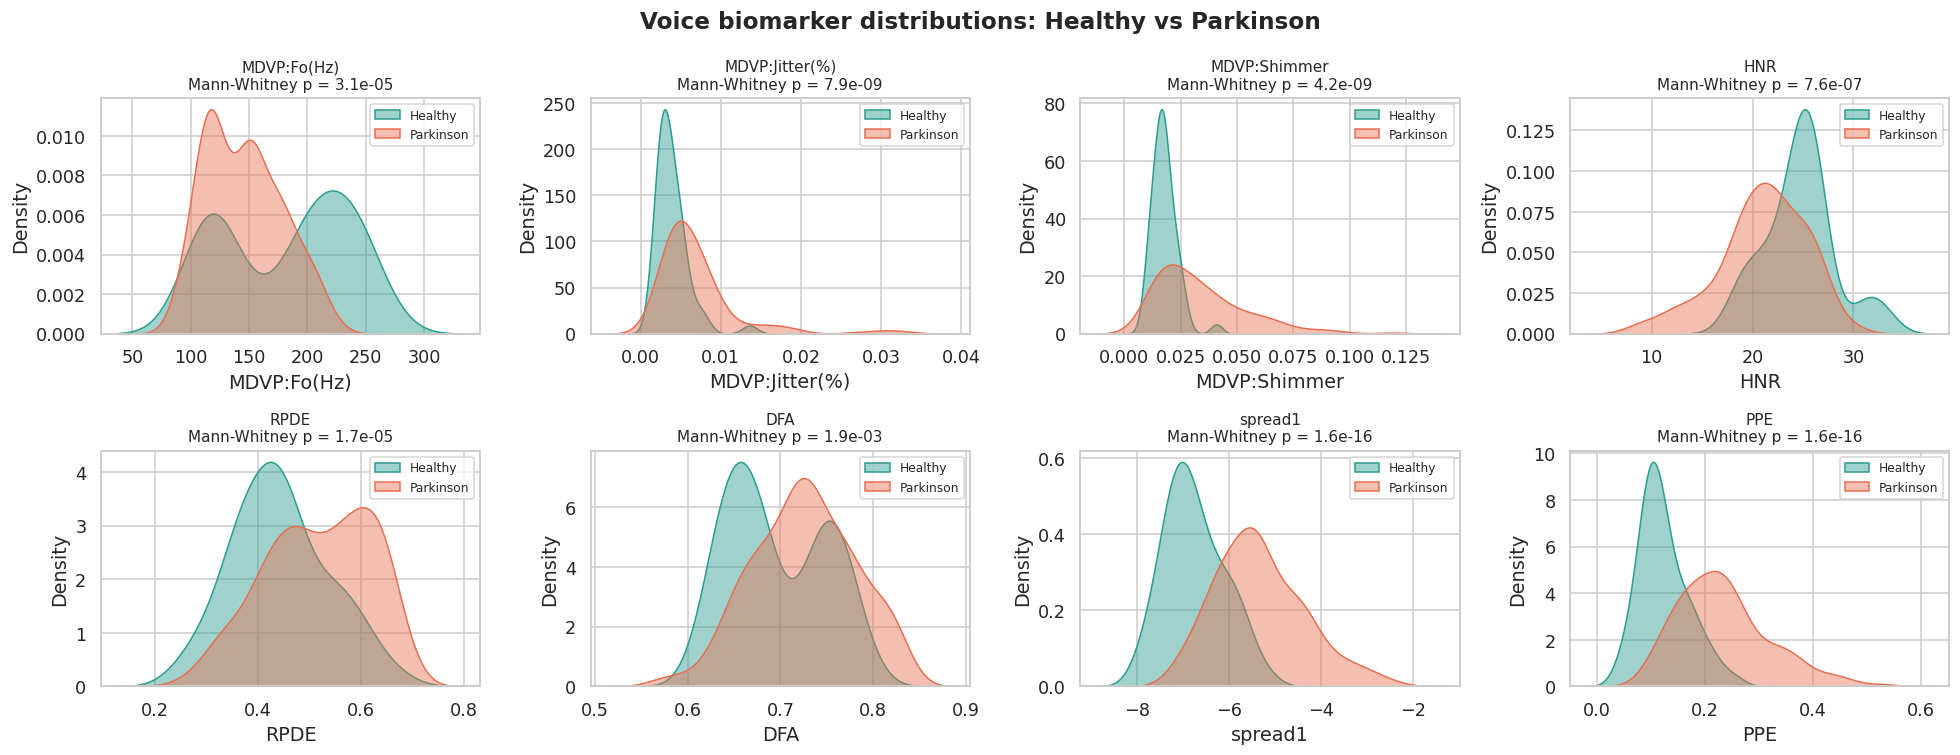

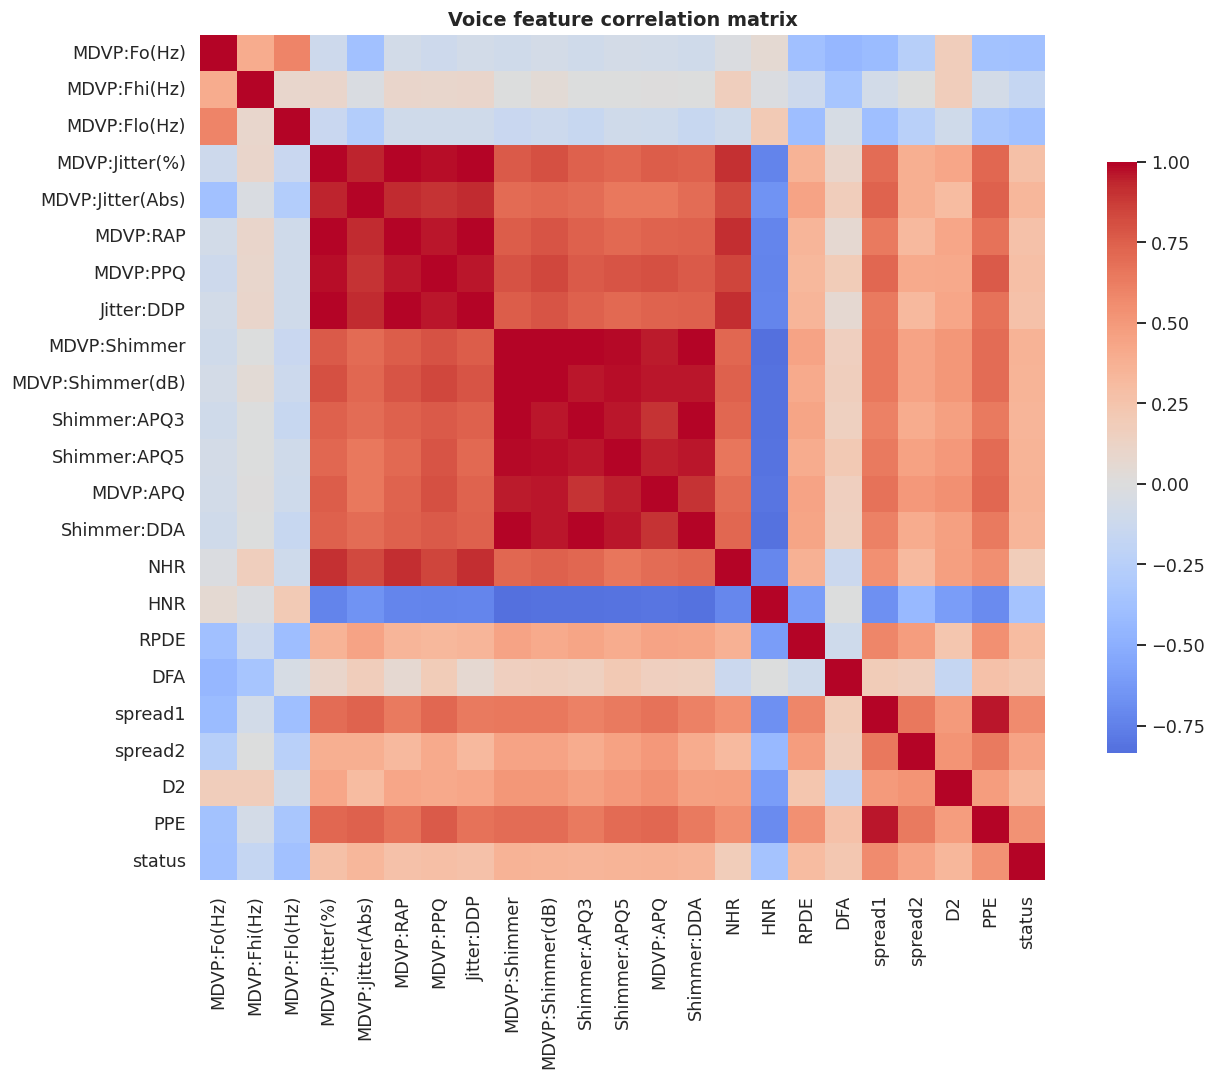

In [3]:
# ============================================================
# STEP 3 — Voice EDA (distribution + correlation)
# ============================================================
key_feats = ['MDVP:Fo(Hz)', 'MDVP:Jitter(%)', 'MDVP:Shimmer', 'HNR', 'RPDE', 'DFA', 'spread1', 'PPE']
key_feats = [f for f in key_feats if f in VOICE_FEATURES]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, f in zip(axes.ravel(), key_feats):
    for lbl, col in [(0, '#2a9d8f'), (1, '#e76f51')]:
        sns.kdeplot(voice_df.loc[voice_df.status == lbl, f], ax=ax, fill=True, alpha=.45,
                    color=col, label=CLASS_NAMES[lbl])
    t, p = stats.mannwhitneyu(voice_df.loc[voice_df.status == 0, f], voice_df.loc[voice_df.status == 1, f])
    ax.set_title(f'{f}\nMann-Whitney p = {p:.1e}', fontsize=10)
    ax.legend(fontsize=8)
plt.suptitle('Voice biomarker distributions: Healthy vs Parkinson', fontweight='bold')
plt.tight_layout(); savefig('fig01_voice_distributions.png'); plt.show()

plt.figure(figsize=(13, 10))
sns.heatmap(voice_df[VOICE_FEATURES + ['status']].corr(), cmap='coolwarm', center=0,
            square=True, cbar_kws={'shrink': .7})
plt.title('Voice feature correlation matrix', fontweight='bold')
plt.tight_layout(); savefig('fig02_voice_correlation.png'); plt.show()

In [4]:
# ============================================================
# STEP 4 — Drawing dataset (auto download from GitHub — no upload needed)
# ============================================================
# Spiral/Wave drawings (Zham et al., 2017; same 204 images as the Kaggle
# "parkinsons-drawings" set) mirrored in a public GitHub repo.
# Only the image folders are downloaded (sparse checkout, ~few MB).
import subprocess
DRAW_REPO = 'https://github.com/gina-santana/Parkinsons_image_classification.git'
REPO_DIR  = os.path.join(DATA_DIR, 'github_drawings')

def download_drawings():
    if glob.glob(os.path.join(REPO_DIR, 'data', '**', '*.png'), recursive=True):
        print('📂 Drawings already downloaded'); return True
    try:
        shutil.rmtree(REPO_DIR, ignore_errors=True)
        subprocess.run(['git', 'clone', '-q', '--depth', '1', '--filter=blob:none', '--sparse', DRAW_REPO, REPO_DIR], check=True)
        subprocess.run(['git', '-C', REPO_DIR, 'sparse-checkout', 'set', 'data/spiral', 'data/wave'], check=True)
        print('🌐 Drawings downloaded from GitHub')
        return True
    except Exception as e:
        print('GitHub download failed:', e); return False

if not download_drawings():
    # Fallback: local / uploaded PD-Dataset.zip
    ZIP_PATH = os.path.join(BASE_DIR, 'PD-Dataset.zip')
    if not os.path.exists(ZIP_PATH) and IN_COLAB:
        print('⬆️ Upload PD-Dataset.zip')
        up = colab_files.upload()
        ZIP_PATH = os.path.join(BASE_DIR, list(up.keys())[0])
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')
records, seen = [], set()
for path in sorted(glob.glob(os.path.join(DATA_DIR, '**', '*'), recursive=True)):
    if not path.lower().endswith(IMG_EXT):
        continue
    parts = path.replace('\\', '/').lower().split('/')
    shape = 'spiral' if 'spiral' in parts else 'wave' if 'wave' in parts else None
    split = 'train' if 'training' in parts else 'test' if 'testing' in parts else None
    label = 1 if 'parkinson' in parts else 0 if 'healthy' in parts else None
    if None in (shape, split, label):
        continue
    key = (shape, split, label, os.path.basename(path))   # removes the duplicate 'drawings/' copy
    if key in seen:
        continue
    seen.add(key)
    records.append(dict(path=path, shape=shape, split=split, label=label))

draw_df = pd.DataFrame(records)
print(draw_df.groupby(['split', 'shape', 'label']).size().unstack(fill_value=0).rename(columns={0: 'Healthy', 1: 'Parkinson'}))
print('Total unique images:', len(draw_df))

🌐 Drawings downloaded from GitHub
label         Healthy  Parkinson
split shape                     
test  spiral       15         15
      wave         15         15
train spiral       36         36
      wave         36         36
Total unique images: 204


🌐 Sakar (2019) loaded from tidymodels/modeldata (subject-level averages)
UCI-Little (2007) : 195 recordings / 32 subject IDs, 22 features | PD = 147 | Healthy = 48
Sakar (2019)      : 252 subjects (1 row each), 751 features | PD = 188 | Healthy = 64


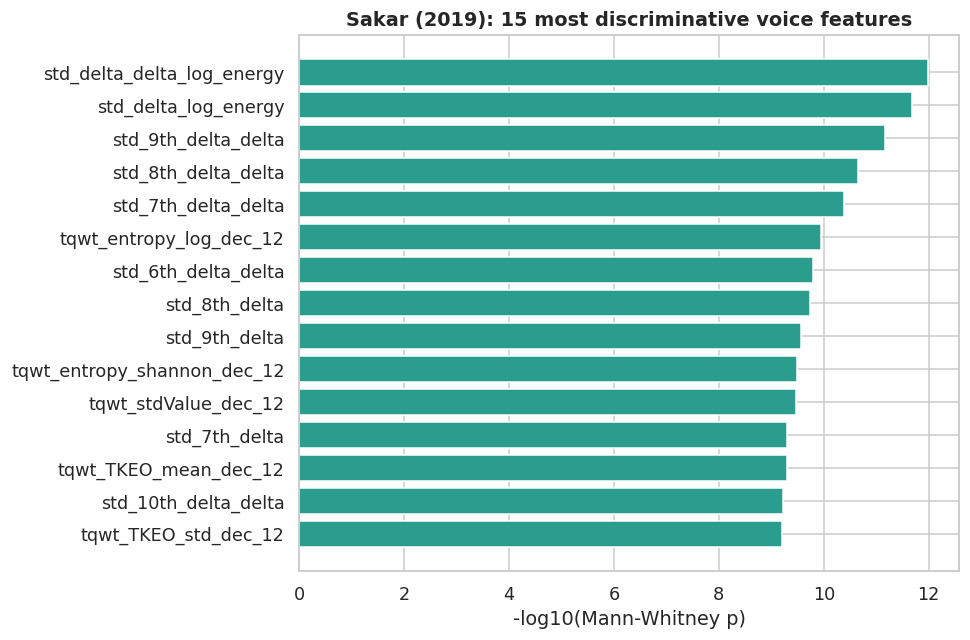

In [5]:
# ============================================================
# STEP 4B — Second voice cohort: Sakar et al. (2019) — 252 subjects (auto download)
# ============================================================
SAKAR_RDA   = 'https://raw.githubusercontent.com/tidymodels/modeldata/00f1e0a7d1a08d38da02c09133f7f90b2efae318/data/pd_speech.rda'
LOCAL_SAKAR = os.path.join(BASE_DIR, 'pd_speech.rda')

def load_sakar():
    try:   # tidymodels/modeldata copy of the UCI file, already averaged over the 3 recordings per subject
        if not os.path.exists(LOCAL_SAKAR):
            urllib.request.urlretrieve(SAKAR_RDA, LOCAL_SAKAR)
        import pyreadr
        df = pyreadr.read_r(LOCAL_SAKAR)['pd_speech']
        df['status'] = (df['class'].astype(str) == 'PD').astype(int)
        print('🌐 Sakar (2019) loaded from tidymodels/modeldata (subject-level averages)')
        return df.drop(columns='class')
    except Exception as e:
        print('modeldata mirror failed:', e)
    from ucimlrepo import fetch_ucirepo     # fallback: UCI id 470 → average the 3 recordings per subject
    ds = fetch_ucirepo(id=470)
    idc, tgt = ds.data.ids.columns[0], ds.data.targets.columns[0]
    df = pd.concat([ds.data.ids, ds.data.features, ds.data.targets], axis=1).groupby(idc).mean(numeric_only=True).reset_index(drop=True)
    df = df.rename(columns={tgt: 'status'}); df['status'] = df['status'].round().astype(int)
    print('🌐 Sakar (2019) loaded via ucimlrepo (averaged per subject)')
    return df

sak_df = load_sakar()
SAKAR_FEATURES = [c for c in sak_df.columns if c != 'status']
sak_df[SAKAR_FEATURES] = sak_df[SAKAR_FEATURES].fillna(sak_df[SAKAR_FEATURES].median())

COHORTS = {
    'UCI-Little (2007)': dict(X=Xv_all, y=yv_all, g=gv_all, features=VOICE_FEATURES,
                              desc=f'{len(yv_all)} recordings / {len(set(gv_all))} subject IDs, {len(VOICE_FEATURES)} features'),
    'Sakar (2019)': dict(X=sak_df[SAKAR_FEATURES].values.astype(np.float32), y=sak_df.status.values.astype(int),
                         g=np.array([f'S{i:03d}' for i in range(len(sak_df))]), features=SAKAR_FEATURES,
                         desc=f'{len(sak_df)} subjects (1 row each), {len(SAKAR_FEATURES)} features'),
}
for C in COHORTS.values():
    C['spw'] = float((C['y'] == 0).sum() / (C['y'] == 1).sum())     # XGBoost weight for class imbalance
for c, C in COHORTS.items():
    print(f'{c:18s}: {C["desc"]} | PD = {C["y"].sum()} | Healthy = {(C["y"] == 0).sum()}')

# quick EDA: strongest Sakar biomarkers (Mann-Whitney)
pv = [stats.mannwhitneyu(sak_df.loc[sak_df.status == 0, f], sak_df.loc[sak_df.status == 1, f]).pvalue for f in SAKAR_FEATURES]
top = pd.DataFrame({'Feature': SAKAR_FEATURES, 'p': pv}).sort_values('p').head(15)
plt.figure(figsize=(9, 6))
plt.barh(top.Feature, -np.log10(top.p), color='#2a9d8f'); plt.gca().invert_yaxis()
plt.xlabel('-log10(Mann-Whitney p)'); plt.title('Sakar (2019): 15 most discriminative voice features', fontweight='bold')
plt.tight_layout(); savefig('fig02b_sakar_top_features.png'); plt.show()

In [6]:
# ============================================================
# STEP 5 — Drawing features: MobileNetV2 (frozen) + HOG + LBP
#   Both feature sets are kept; the better one is chosen by TRAIN cross-validation (STEP 7)
# ============================================================
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Input
from tensorflow.keras.models import Model
print('TensorFlow', tf.__version__, '| GPU:', bool(tf.config.list_physical_devices('GPU')))

def mobilenet_base():
    return MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

def build_cnn_extractor():
    base = mobilenet_base(); base.trainable = False
    inp = Input(shape=(224, 224, 3))
    out = GlobalAveragePooling2D()(base(inp, training=False))
    return Model(inp, out, name='mobilenetv2_gap_extractor')

def load_rgb(path):
    return np.array(Image.open(path).convert('RGB').resize((224, 224), Image.LANCZOS), dtype=np.float32)

def cnn_features(paths, extractor, batch=32):
    feats = []
    for i in range(0, len(paths), batch):
        feats.append(extractor.predict(preprocess_input(np.stack([load_rgb(p) for p in paths[i:i + batch]])), verbose=0))
    return np.vstack(feats)

def handcrafted_features(path):
    g = np.array(Image.open(path).convert('L').resize((128, 128), Image.LANCZOS), dtype=np.float32) / 255.
    h = hog(g, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys')
    lbp = local_binary_pattern((g * 255).astype(np.uint8), P=24, R=3, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=26, range=(0, 26), density=True)
    return np.concatenate([h, lbp_hist])

def drawing_features(paths, feature_set):
    F = cnn_features(list(paths), cnn_extractor)
    if feature_set == 'hybrid':
        F = np.hstack([F, np.vstack([handcrafted_features(p) for p in paths])])
    return F.astype(np.float32)

t0 = time.time()
cnn_extractor = build_cnn_extractor()
F_cnn = cnn_features(draw_df.path.tolist(), cnn_extractor)
F_hc  = np.vstack([handcrafted_features(p) for p in draw_df.path])
T_FEAT = time.time() - t0
FEATURE_SETS = {'cnn': F_cnn.astype(np.float32), 'hybrid': np.hstack([F_cnn, F_hc]).astype(np.float32)}
FS_LABEL = {'cnn': 'CNN (MobileNetV2)', 'hybrid': 'Hybrid (CNN+HOG+LBP)'}

tr_mask = (draw_df.split == 'train').values
yd_tr, yd_te = draw_df.label.values[tr_mask], draw_df.label.values[~tr_mask]
print(f'✅ CNN {F_cnn.shape[1]}-D | HOG+LBP {F_hc.shape[1]}-D | extraction {T_FEAT:.1f}s for {len(draw_df)} images')

TensorFlow 2.21.0 | GPU: False
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ CNN 1280-D | HOG+LBP 8126-D | extraction 39.9s for 204 images


In [7]:
# ============================================================
# STEP 6 — Class-balanced model zoo, pipelines, metrics, calibration
# ============================================================
def model_zoo(scale_pos_weight=1.0):
    svm = SVC(kernel='rbf', C=10, gamma='scale', probability=True, class_weight='balanced', random_state=SEED)
    rf  = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=SEED, n_jobs=-1)
    xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.9, colsample_bytree=0.8,
                        scale_pos_weight=scale_pos_weight, eval_metric='logloss', random_state=SEED, n_jobs=-1)
    lr  = LogisticRegression(C=1.0, max_iter=5000, class_weight='balanced', random_state=SEED)
    knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
    return {
        'SVM (RBF)':     svm,
        'Random Forest': rf,
        'XGBoost':       xgb,
        'Logistic Reg.': lr,
        'KNN':           knn,
        'Soft Voting':   VotingClassifier([('svm', clone(svm)), ('rf', clone(rf)), ('xgb', clone(xgb)), ('lr', clone(lr))], voting='soft'),
        'Stacking':      StackingClassifier([('svm', clone(svm)), ('rf', clone(rf)), ('xgb', clone(xgb))],
                                            final_estimator=LogisticRegression(max_iter=5000, class_weight='balanced'), cv=5),
    }

def make_pipeline(modality, clf):
    if modality == 'drawing':
        return Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=0.95, random_state=SEED)), ('clf', clf)])
    return Pipeline([('scaler', StandardScaler()), ('clf', clf)])

def metrics(y, prob, thr=0.5):
    pred = (np.asarray(prob) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(Accuracy=accuracy_score(y, pred),
                BalAcc=balanced_accuracy_score(y, pred),
                Precision=precision_score(y, pred, zero_division=0),
                Sensitivity=recall_score(y, pred, zero_division=0),
                Specificity=tn / (tn + fp) if (tn + fp) else 0.0,
                F1=f1_score(y, pred, zero_division=0),
                AUC=roc_auc_score(y, prob) if len(np.unique(y)) == 2 else np.nan,
                MCC=matthews_corrcoef(y, pred))

def logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps); return np.log(p / (1 - p))

class PlattCalibrator:
    # Maps raw scores to calibrated, prevalence-balanced probabilities (fitted on out-of-fold scores only)
    def fit(self, p, y):
        self.lr = LogisticRegression(C=100, class_weight='balanced', max_iter=1000).fit(logit(p)[:, None], y); return self
    def transform(self, p):
        return self.lr.predict_proba(logit(p)[:, None])[:, 1]

def oof_proba(modality, clf, X, y, groups=None, seed=SEED, n_splits=5):
    if groups is None:
        splits = StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(X, y)
    else:
        splits = StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(X, y, groups)
    o = np.zeros(len(y))
    for a, b in splits:
        o[b] = make_pipeline(modality, clone(clf)).fit(X[a], y[a]).predict_proba(X[b])[:, 1]
    return o

MET = ['Accuracy', 'BalAcc', 'Precision', 'Sensitivity', 'Specificity', 'F1', 'AUC', 'MCC']
print('✅ 7 class-balanced classifiers ready')

✅ 7 class-balanced classifiers ready


In [8]:
# ============================================================
# STEP 7 — DRAWING unimodal: 2 feature sets × 7 classifiers (official train/test split)
# ============================================================
# Feature set AND classifier are selected by TRAIN 5-fold CV AUC only (no test-set peeking).
cv_d = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(np.zeros(len(yd_tr)), yd_tr))
rows, oof_d, prob_d, fit_d = [], {}, {}, {}
for fs, F in FEATURE_SETS.items():
    Xtr, Xte = F[tr_mask], F[~tr_mask]
    for name, clf in model_zoo().items():
        t0 = time.time()
        o = np.zeros(len(yd_tr))
        for a, b in cv_d:
            o[b] = make_pipeline('drawing', clone(clf)).fit(Xtr[a], yd_tr[a]).predict_proba(Xtr[b])[:, 1]
        pipe = make_pipeline('drawing', clone(clf)).fit(Xtr, yd_tr)
        p = pipe.predict_proba(Xte)[:, 1]
        oof_d[(fs, name)], prob_d[(fs, name)], fit_d[(fs, name)] = o, p, pipe
        m = metrics(yd_te, p)
        rows.append(dict(Modality='Drawing', FeatureSet=FS_LABEL[fs], Model=name, Protocol='official split (144 train / 60 test)',
                         Select_AUC=roc_auc_score(yd_tr, o), **m, **{f'{k}_std': 0.0 for k in m}, Time_s=time.time() - t0))
        print(f'  {FS_LABEL[fs]:22s} | {name:14s} | train-CV AUC {rows[-1]["Select_AUC"]:.3f} | test Acc {m["Accuracy"]:.3f}  AUC {m["AUC"]:.3f}')
res_d = pd.DataFrame(rows)
best_row = res_d.sort_values('Select_AUC', ascending=False).iloc[0]
DRAW_FEATURE_SET = [k for k, v in FS_LABEL.items() if v == best_row.FeatureSet][0]
BEST_D, KEY_D = best_row.Model, (DRAW_FEATURE_SET, best_row.Model)
draw_pipe = fit_d[KEY_D]
Xd_tr, Xd_te = FEATURE_SETS[DRAW_FEATURE_SET][tr_mask], FEATURE_SETS[DRAW_FEATURE_SET][~tr_mask]
cal_d = PlattCalibrator().fit(oof_d[KEY_D], yd_tr)
REL_D = max(roc_auc_score(yd_tr, oof_d[KEY_D]) - 0.5, 0.01)          # reliability used by ACWF
a_tr, a_te = cal_d.transform(oof_d[KEY_D]), cal_d.transform(prob_d[KEY_D])
print(f'\n🏆 Best drawing configuration (by train CV): {FS_LABEL[DRAW_FEATURE_SET]} + {BEST_D}')
print('Feature-set ablation (mean test accuracy over 7 classifiers):')
print(res_d.groupby('FeatureSet')[['Select_AUC', 'Accuracy', 'AUC']].mean().round(4))

  CNN (MobileNetV2)      | SVM (RBF)      | train-CV AUC 0.941 | test Acc 0.833  AUC 0.924
  CNN (MobileNetV2)      | Random Forest  | train-CV AUC 0.897 | test Acc 0.783  AUC 0.870
  CNN (MobileNetV2)      | XGBoost        | train-CV AUC 0.884 | test Acc 0.800  AUC 0.917
  CNN (MobileNetV2)      | Logistic Reg.  | train-CV AUC 0.928 | test Acc 0.850  AUC 0.941
  CNN (MobileNetV2)      | KNN            | train-CV AUC 0.854 | test Acc 0.750  AUC 0.868
  CNN (MobileNetV2)      | Soft Voting    | train-CV AUC 0.931 | test Acc 0.817  AUC 0.931
  CNN (MobileNetV2)      | Stacking       | train-CV AUC 0.938 | test Acc 0.817  AUC 0.926
  Hybrid (CNN+HOG+LBP)   | SVM (RBF)      | train-CV AUC 0.921 | test Acc 0.767  AUC 0.899
  Hybrid (CNN+HOG+LBP)   | Random Forest  | train-CV AUC 0.857 | test Acc 0.733  AUC 0.868
  Hybrid (CNN+HOG+LBP)   | XGBoost        | train-CV AUC 0.821 | test Acc 0.800  AUC 0.870
  Hybrid (CNN+HOG+LBP)   | Logistic Reg.  | train-CV AUC 0.887 | test Acc 0.800  AUC 0.902

  fine-tune seed 0: Acc 0.850 | AUC 0.866 | 28 epochs | 248s


  fine-tune seed 1: Acc 0.833 | AUC 0.858 | 32 epochs | 327s
  fine-tune seed 2: Acc 0.783 | AUC 0.871 | 36 epochs | 327s


,Approach,Accuracy,Acc_std,AUC,Trainable_CNN_params,Train_time_s,Model_size_MB,Latency_ms
0,Proposed hybrid: frozen MobileNetV2 + CNN (Mob...,0.833,0.000,0.924,0,28.611,10.224,173.427
1,"Fine-tuned MobileNetV2 (end-to-end, augmentation)",0.822,0.035,0.865,1512001,300.710,21.737,126.093


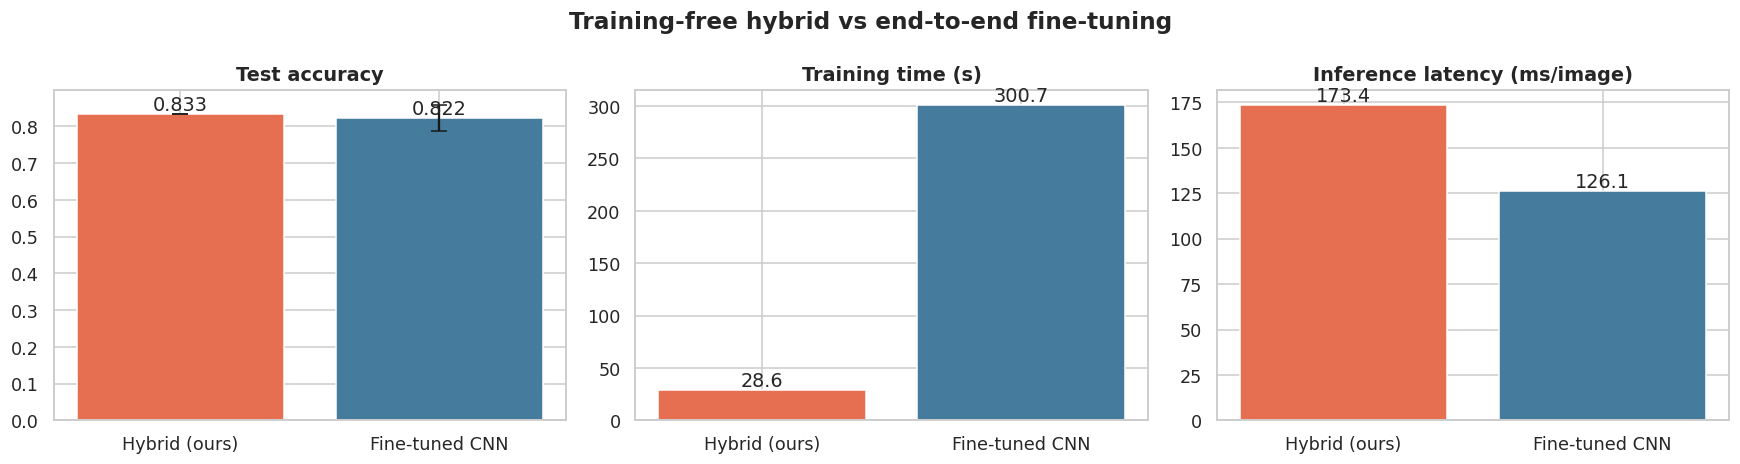

In [9]:
# ============================================================
# STEP 8 — Baseline: end-to-end FINE-TUNED MobileNetV2 vs our training-free hybrid
#   (answers the reviewer question "why not just fine-tune a CNN?")
# ============================================================
from tensorflow.keras import layers, callbacks, optimizers

def load_batch(paths):
    return preprocess_input(np.stack([load_rgb(p) for p in paths]))

def build_finetune():
    base = mobilenet_base(); base.trainable = False
    inp = Input((224, 224, 3))
    x = layers.RandomFlip('horizontal')(inp)
    x = layers.RandomRotation(0.05)(x)
    x = layers.RandomZoom(0.1)(x)
    x = GlobalAveragePooling2D()(base(x, training=False))
    x = layers.Dropout(0.3)(x)
    return Model(inp, layers.Dense(1, activation='sigmoid')(x)), base

def latency_ms(fn, n=20):
    fn(); t = time.time()
    for _ in range(n): fn()
    return (time.time() - t) / n * 1000

def file_mb(path):
    return os.path.getsize(path) / 1e6

ft_rows, ft_model = [], None
if RUN_FINETUNE:
    Xi_tr = load_batch(draw_df.path[tr_mask].tolist()); Xi_te = load_batch(draw_df.path[~tr_mask].tolist())
    for seed in FT_SEEDS:
        tf.keras.utils.set_random_seed(seed)
        tr_i, va_i = next(StratifiedKFold(5, shuffle=True, random_state=seed).split(Xi_tr, yd_tr))
        model, base = build_finetune()
        es = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
        t0 = time.time()
        model.compile(optimizers.Adam(1e-3), 'binary_crossentropy', metrics=['accuracy'])
        h1 = model.fit(Xi_tr[tr_i], yd_tr[tr_i], validation_data=(Xi_tr[va_i], yd_tr[va_i]),
                       epochs=FT_EPOCHS, batch_size=16, callbacks=[es], verbose=0)
        base.trainable = True
        for l in base.layers[:-30]: l.trainable = False
        for l in base.layers:
            if isinstance(l, layers.BatchNormalization): l.trainable = False
        model.compile(optimizers.Adam(1e-5), 'binary_crossentropy', metrics=['accuracy'])
        h2 = model.fit(Xi_tr[tr_i], yd_tr[tr_i], validation_data=(Xi_tr[va_i], yd_tr[va_i]),
                       epochs=FT_EPOCHS, batch_size=16, callbacks=[es], verbose=0)
        train_s = time.time() - t0
        p = model.predict(Xi_te, verbose=0).ravel()
        trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
        ft_rows.append(dict(Seed=seed, **metrics(yd_te, p), Train_s=train_s, Epochs=len(h1.history['loss']) + len(h2.history['loss']),
                            Trainable_params=trainable))
        print(f'  fine-tune seed {seed}: Acc {ft_rows[-1]["Accuracy"]:.3f} | AUC {ft_rows[-1]["AUC"]:.3f} | '
              f'{ft_rows[-1]["Epochs"]} epochs | {train_s:.0f}s')
        ft_model = model
    ft_df = pd.DataFrame(ft_rows)

    # ---------- lightweight comparison (accuracy vs cost) ----------
    tmp = os.path.join(OUT_DIR, '_tmp'); os.makedirs(tmp, exist_ok=True)
    cnn_extractor.save(os.path.join(tmp, 'ext.keras')); joblib.dump(draw_pipe, os.path.join(tmp, 'clf.pkl'))
    ft_model.save(os.path.join(tmp, 'ft.keras'))
    one = draw_df.path[~tr_mask].iloc[0]
    hyb_lat = latency_ms(lambda: draw_pipe.predict_proba(drawing_features([one], DRAW_FEATURE_SET)))
    ft_lat  = latency_ms(lambda: ft_model.predict(load_batch([one]), verbose=0))
    hyb_train = T_FEAT * tr_mask.mean() + res_d.set_index(['FeatureSet', 'Model']).loc[(FS_LABEL[DRAW_FEATURE_SET], BEST_D), 'Time_s']
    light = pd.DataFrame([
        dict(Approach=f'Proposed hybrid: frozen MobileNetV2 + {FS_LABEL[DRAW_FEATURE_SET]} + {BEST_D}',
             Accuracy=metrics(yd_te, prob_d[KEY_D])['Accuracy'], Acc_std=0.0, AUC=metrics(yd_te, prob_d[KEY_D])['AUC'],
             Trainable_CNN_params=0, Train_time_s=hyb_train,
             Model_size_MB=file_mb(os.path.join(tmp, 'ext.keras')) + file_mb(os.path.join(tmp, 'clf.pkl')), Latency_ms=hyb_lat),
        dict(Approach='Fine-tuned MobileNetV2 (end-to-end, augmentation)',
             Accuracy=ft_df.Accuracy.mean(), Acc_std=ft_df.Accuracy.std(), AUC=ft_df.AUC.mean(),
             Trainable_CNN_params=int(ft_df.Trainable_params.iloc[0]), Train_time_s=ft_df.Train_s.mean(),
             Model_size_MB=file_mb(os.path.join(tmp, 'ft.keras')), Latency_ms=ft_lat)])
    shutil.rmtree(tmp, ignore_errors=True)
    light.to_csv(os.path.join(OUT_DIR, 'lightweight_comparison.csv'), index=False)
    ft_df.to_csv(os.path.join(OUT_DIR, 'finetune_baseline_runs.csv'), index=False)
    display(light.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
    lbl = ['Hybrid (ours)', 'Fine-tuned CNN']
    for ax, col, t in zip(axes, ['Accuracy', 'Train_time_s', 'Latency_ms'], ['Test accuracy', 'Training time (s)', 'Inference latency (ms/image)']):
        ax.bar(lbl, light[col], yerr=light['Acc_std'] if col == 'Accuracy' else None, color=['#e76f51', '#457b9d'], capsize=5)
        for i, v in enumerate(light[col]): ax.text(i, v, f'{v:.3f}' if col == 'Accuracy' else f'{v:.1f}', ha='center', va='bottom')
        ax.set_title(t, fontweight='bold')
    plt.suptitle('Training-free hybrid vs end-to-end fine-tuning', fontweight='bold')
    plt.tight_layout(); savefig('fig12_hybrid_vs_finetune.png'); plt.show()
else:
    print('RUN_FINETUNE = False → skipped')

🌐 NewHandPD: 264 spiral images | 66 people (healthy 35, PD 31)


,Setting,Accuracy,BalAcc,Precision,Sensitivity,Specificity,F1,AUC,MCC
0,Zero-shot transfer (image level),0.4697,0.5000,0.4697,1.0000,0.0000,0.6392,0.5127,0.0000
1,Zero-shot transfer (subject level),0.4697,0.5000,0.4697,1.0000,0.0000,0.6392,0.5023,0.0000
2,"Re-trained, subject-wise 5-fold CV × 3 (mean)",0.9015,0.9036,0.8638,0.9382,0.8690,0.8995,0.9550,0.8059
3,"Re-trained, subject-wise 5-fold CV × 3 (std)",0.0114,0.0116,0.0090,0.0168,0.0082,0.0120,0.0050,0.0233


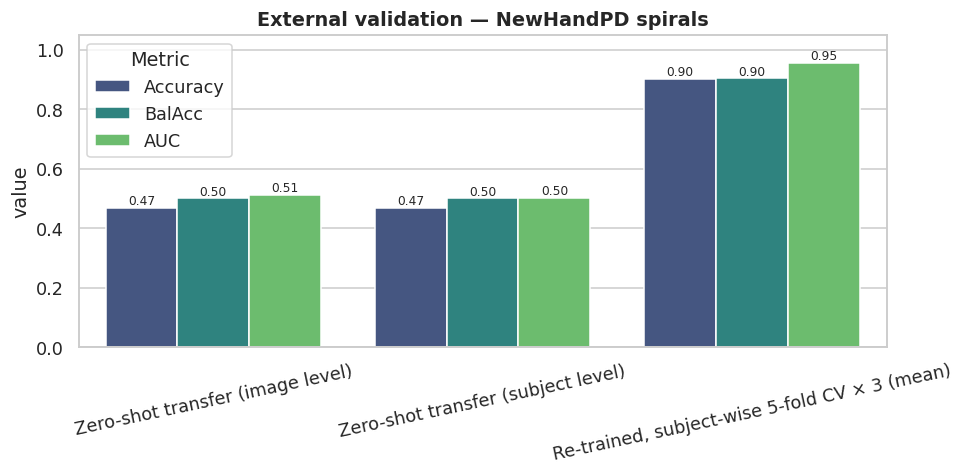

In [10]:
# ============================================================
# STEP 9 — EXTERNAL validation on an independent drawing cohort: NewHandPD spirals
#   (Pereira et al., 2016 — 66 people, UNESP Brazil). Skipped automatically if the site is unreachable.
# ============================================================
import re, urllib.request
NHPD_URLS = {0: 'https://wwwp.fc.unesp.br/~papa/pub/datasets/Handpd/NewHealthy/HealthySpiral.zip',
             1: 'https://wwwp.fc.unesp.br/~papa/pub/datasets/Handpd/NewPatients/PatientSpiral.zip'}
EXT_DIR, EXT_OK, ext_results = os.path.join(DATA_DIR, 'NewHandPD'), False, None
if RUN_EXTERNAL:
    try:
        os.makedirs(EXT_DIR, exist_ok=True); recs = []
        for lab, url in NHPD_URLS.items():
            zp, out = os.path.join(EXT_DIR, f'{lab}.zip'), os.path.join(EXT_DIR, str(lab))
            if not os.path.exists(zp): urllib.request.urlretrieve(url, zp)
            if not os.path.isdir(out): zipfile.ZipFile(zp).extractall(out)
            for p in sorted(glob.glob(os.path.join(out, '**', '*'), recursive=True)):
                if p.lower().endswith(IMG_EXT) and '__macosx' not in p.lower():
                    m = re.search(r'-([HP])(\d+)', os.path.basename(p))
                    recs.append(dict(path=p, label=lab, subject=f'{lab}_{m.group(2)}' if m else f'{lab}_{os.path.basename(p)}'))
        ext_df = pd.DataFrame(recs)
        assert ext_df.label.nunique() == 2, 'need both classes'
        EXT_OK = True
        print(f'🌐 NewHandPD: {len(ext_df)} spiral images | {ext_df.subject.nunique()} people '
              f'(healthy {ext_df[ext_df.label==0].subject.nunique()}, PD {ext_df[ext_df.label==1].subject.nunique()})')
    except Exception as e:
        print('⚠️ External dataset not available — skipping this step:', e)

if EXT_OK:
    F_ext = drawing_features(ext_df.path.tolist(), DRAW_FEATURE_SET)
    y_ext, g_ext = ext_df.label.values, ext_df.subject.values
    # (i) zero-shot transfer: model trained on the Kaggle drawings, tested on NewHandPD as-is
    p0 = cal_d.transform(draw_pipe.predict_proba(F_ext)[:, 1])
    sp = pd.DataFrame({'g': g_ext, 'p': p0, 'y': y_ext}).groupby('g').mean()
    zs_img, zs_subj = metrics(y_ext, p0), metrics(sp.y.astype(int).values, sp.p.values)
    # (ii) same pipeline re-trained on NewHandPD with subject-wise 5-fold CV × 3
    reps = []
    for k in range(3):
        o = oof_proba('drawing', model_zoo()[BEST_D], F_ext, y_ext, g_ext, seed=SEED + k)
        reps.append(metrics(y_ext, o))
    cv = pd.DataFrame(reps)
    ext_results = pd.DataFrame([
        dict(Setting='Zero-shot transfer (image level)', **zs_img),
        dict(Setting='Zero-shot transfer (subject level)', **zs_subj),
        dict(Setting='Re-trained, subject-wise 5-fold CV × 3 (mean)', **cv.mean().to_dict()),
        dict(Setting='Re-trained, subject-wise 5-fold CV × 3 (std)', **cv.std().to_dict())])
    ext_results.to_csv(os.path.join(OUT_DIR, 'external_validation_newhandpd.csv'), index=False)
    display(ext_results.round(4))

    plt.figure(figsize=(9, 4.5))
    d = ext_results.iloc[[0, 1, 2]].melt(id_vars='Setting', value_vars=['Accuracy', 'BalAcc', 'AUC'], var_name='Metric')
    ax = sns.barplot(data=d, x='Setting', y='value', hue='Metric', palette='viridis')
    for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=8)
    ax.set_ylim(0, 1.05); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=12)
    plt.title('External validation — NewHandPD spirals', fontweight='bold')
    plt.tight_layout(); savefig('fig13_external_validation.png'); plt.show()

In [11]:
# ============================================================
# STEP 10 — VOICE unimodal for BOTH cohorts: repeated SUBJECT-WISE 5-fold CV
# ============================================================
res_v, voice_oof = {}, {}
for cname, C in COHORTS.items():
    print(f'🎙️ {cname} — {C["desc"]}')
    rows, voice_oof[cname] = [], {}
    for name, clf in model_zoo(C['spw']).items():
        t0, reps, subj_b = time.time(), [], []
        for k in range(N_VOICE_REPEATS):
            o = oof_proba('voice', clf, C['X'], C['y'], C['g'], seed=SEED + k)
            voice_oof[cname].setdefault(name, []).append(o)
            reps.append(metrics(C['y'], o))
            sp = pd.DataFrame({'g': C['g'], 'p': o, 'y': C['y']}).groupby('g').mean()
            subj_b.append(balanced_accuracy_score(sp.y.astype(int), (sp.p >= .5).astype(int)))
        R = pd.DataFrame(reps)
        rows.append(dict(Modality=f'Voice — {cname}', FeatureSet=f'{len(C["features"])} acoustic features', Model=name,
                         Protocol=f'subject-wise 5-fold CV × {N_VOICE_REPEATS}', Select_AUC=R.AUC.mean(),
                         **R.mean().to_dict(), **{f'{c}_std': R[c].std() for c in R},
                         Subject_BalAcc=np.mean(subj_b), Time_s=time.time() - t0))
        print(f'   {name:14s} | AUC {R.AUC.mean():.3f} ± {R.AUC.std():.3f} | BalAcc {R.BalAcc.mean():.3f} | subject BalAcc {np.mean(subj_b):.3f} | {time.time()-t0:.0f}s')
    res_v[cname] = pd.DataFrame(rows)
    C['best'] = res_v[cname].sort_values(['Select_AUC', 'BalAcc'], ascending=False).Model.iloc[0]
    print(f'   🏆 best: {C["best"]}\n')

unimodal = pd.concat([res_d] + list(res_v.values()), ignore_index=True)
unimodal.to_csv(os.path.join(OUT_DIR, 'unimodal_all_models.csv'), index=False)
display(unimodal[['Modality', 'FeatureSet', 'Model', 'Accuracy', 'BalAcc', 'Sensitivity', 'Specificity', 'F1', 'AUC', 'MCC']].round(4))

🎙️ UCI-Little (2007) — 195 recordings / 32 subject IDs, 22 features
   SVM (RBF)      | AUC 0.675 ± 0.039 | BalAcc 0.601 | subject BalAcc 0.613 | 0s
   Random Forest  | AUC 0.755 ± 0.012 | BalAcc 0.606 | subject BalAcc 0.629 | 20s
   XGBoost        | AUC 0.802 ± 0.041 | BalAcc 0.673 | subject BalAcc 0.696 | 2s
   Logistic Reg.  | AUC 0.766 ± 0.015 | BalAcc 0.654 | subject BalAcc 0.683 | 0s
   KNN            | AUC 0.740 ± 0.036 | BalAcc 0.610 | subject BalAcc 0.637 | 0s
   Soft Voting    | AUC 0.771 ± 0.016 | BalAcc 0.641 | subject BalAcc 0.683 | 23s
   Stacking       | AUC 0.691 ± 0.037 | BalAcc 0.648 | subject BalAcc 0.675 | 122s
   🏆 best: XGBoost

🎙️ Sakar (2019) — 252 subjects (1 row each), 751 features
   SVM (RBF)      | AUC 0.817 ± 0.009 | BalAcc 0.681 | subject BalAcc 0.681 | 2s
   Random Forest  | AUC 0.840 ± 0.006 | BalAcc 0.675 | subject BalAcc 0.675 | 33s
   XGBoost        | AUC 0.850 ± 0.011 | BalAcc 0.728 | subject BalAcc 0.728 | 54s
   Logistic Reg.  | AUC 0.807 ± 0.018 

,Modality,FeatureSet,Model,Accuracy,BalAcc,Sensitivity,Specificity,F1,AUC,MCC
0,Drawing,CNN (MobileNetV2),SVM (RBF),0.8333,0.8333,0.8000,0.8667,0.8276,0.9244,0.6682
1,Drawing,CNN (MobileNetV2),Random Forest,0.7833,0.7833,0.7000,0.8667,0.7636,0.8700,0.5747
2,Drawing,CNN (MobileNetV2),XGBoost,0.8000,0.8000,0.7667,0.8333,0.7931,0.9167,0.6013
3,Drawing,CNN (MobileNetV2),Logistic Reg.,0.8500,0.8500,0.8667,0.8333,0.8525,0.9411,0.7004
4,Drawing,CNN (MobileNetV2),KNN,0.7500,0.7500,0.5667,0.9333,0.6939,0.8683,0.5374
5,Drawing,CNN (MobileNetV2),Soft Voting,0.8167,0.8167,0.8000,0.8333,0.8136,0.9311,0.6337
6,Drawing,CNN (MobileNetV2),Stacking,0.8167,0.8167,0.8000,0.8333,0.8136,0.9256,0.6337
7,Drawing,Hybrid (CNN+HOG+LBP),SVM (RBF),0.7667,0.7667,0.5667,0.9667,0.7083,0.8989,0.5819
8,Drawing,Hybrid (CNN+HOG+LBP),Random Forest,0.7333,0.7333,0.5333,0.9333,0.6667,0.8683,0.5092
9,Drawing,Hybrid (CNN+HOG+LBP),XGBoost,0.8000,0.8000,0.6667,0.9333,0.7692,0.8700,0.6225


In [12]:
# ============================================================
# STEP 11 — Fusion engine
#   each repetition: new subject-wise voice split → voice model + calibrator trained on train subjects
#   → class-matched pairing at error-correlation level rho → 6 fusion strategies learned on TRAIN pairs
# ============================================================
VOICE_TEST_FRAC = 0.30
W_GRID     = np.round(np.arange(0, 1.0001, 0.05), 2)
GAMMA_GRID = [0.0, 0.5, 1.0, 2.0]
NOISE      = [0.0, 0.1, 0.25, 0.5, 1.0, 2.0]
STRATS = ['Weighted Late Fusion', 'Product Rule', 'Meta-Learner (LR)',
          'Early Fusion (SVM)', 'Early Fusion (XGB)', 'ACWF (proposed)']
LOG_KEYS = ['Drawing only', 'Voice only (subject-wise test)', 'Voice only (paired rows)'] + STRATS
Zd_tr, Zd_te = Pipeline(draw_pipe.steps[:-1]).transform(Xd_tr), Pipeline(draw_pipe.steps[:-1]).transform(Xd_te)

def split_voice_subjects(C, r):
    subj = pd.Series(C['y'], index=C['g']).groupby(level=0).first()
    rng, test_subj = np.random.default_rng(1000 + r), []
    for c in (0, 1):
        s = subj.index[subj.values == c].values
        test_subj += list(rng.choice(s, max(2, int(round(len(s) * VOICE_TEST_FRAC))), replace=False))
    te = np.isin(C['g'], test_subj)
    return np.where(~te)[0], np.where(te)[0]

def pair_samples(y_d, p_d, y_v, p_v, rho, rng):
    # Class-matched pseudo-pairing with controllable error correlation (Gaussian-copula style):
    #   rho = 0 → independent random pairing (standard simulated cohort)
    #   rho = 1 → the drawing that is hardest to classify is paired with the hardest voice sample
    #             (errors co-occur — worst case for fusion, closer to real patients)
    idx = np.empty(len(y_d), dtype=int)
    for c in (0, 1):
        pos, pool = np.where(y_d == c)[0], np.where(y_v == c)[0]
        cand = rng.choice(pool, size=len(pos), replace=len(pool) < len(pos))
        if rho <= 0:
            idx[pos] = cand; continue
        conf_d = p_d[pos] if c == 1 else 1 - p_d[pos]            # confidence in the TRUE class
        conf_v = p_v[cand] if c == 1 else 1 - p_v[cand]
        z = stats.norm.ppf((stats.rankdata(conf_d) - 0.5) / len(pos))
        latent = rho * z + np.sqrt(max(1 - rho ** 2, 0)) * rng.normal(size=len(pos))
        idx[pos[np.argsort(latent)]] = cand[np.argsort(conf_v)]
    return idx

def product_rule(a, b):
    m = a * b; return m / (m + (1 - a) * (1 - b) + 1e-12)

def acwf(pd_, pv_, rel_d, rel_v, gamma):
    # Adaptive Confidence-Weighted Fusion: calibrated logits weighted by
    # modality reliability (train OOF AUC − 0.5) × per-sample confidence |2p − 1|^gamma
    cd = rel_d * np.abs(2 * pd_ - 1) ** gamma + 1e-9
    cv = rel_v * np.abs(2 * pv_ - 1) ** gamma + 1e-9
    return 1 / (1 + np.exp(-(cd * logit(pd_) + cv * logit(pv_)) / (cd + cv)))

def error_corr(y, a, b):
    ea, eb = ((a >= .5) != y).astype(float), ((b >= .5) != y).astype(float)
    return float(np.corrcoef(ea, eb)[0, 1]) if ea.std() > 0 and eb.std() > 0 else 0.0

def run_fusion(C, rhos=(0.0,), R=N_PAIRINGS, noise=False):
    X, y, g = C['X'], C['y'], C['g']
    out = {rho: dict(log={k: [] for k in LOG_KEYS}, sweep=[], err=[], store=[]) for rho in rhos}
    rob, t_start = [], time.time()
    proto = model_zoo(C['spw'])[C['best']]
    for r in range(R):
        vtr, vte = split_voice_subjects(C, r)
        assert not set(g[vtr]) & set(g[vte])
        o_v    = oof_proba('voice', proto, X[vtr], y[vtr], g[vtr], seed=SEED + r)
        pipe_v = make_pipeline('voice', clone(proto)).fit(X[vtr], y[vtr])
        cal_v  = PlattCalibrator().fit(o_v, y[vtr])
        rel_v  = max(roc_auc_score(y[vtr], o_v) - 0.5, 0.01)
        pv_tr_all = cal_v.transform(o_v)
        pv_te_all = cal_v.transform(pipe_v.predict_proba(X[vte])[:, 1])
        vsc = StandardScaler().fit(X[vtr]); Vtr, Vte = vsc.transform(X[vtr]), vsc.transform(X[vte])
        for rho in rhos:
            rng = np.random.default_rng(SEED + 1000 * r + int(round(rho * 100)))
            jtr = pair_samples(yd_tr, a_tr, y[vtr], pv_tr_all, rho, rng)
            jte = pair_samples(yd_te, a_te, y[vte], pv_te_all, rho, rng)
            b_tr, b_te = pv_tr_all[jtr], pv_te_all[jte]
            # ---- fusion parameters learned on TRAIN pairs only ----
            sc = [(accuracy_score(yd_tr, (w * a_tr + (1 - w) * b_tr >= .5).astype(int)),
                   roc_auc_score(yd_tr, w * a_tr + (1 - w) * b_tr), -abs(w - .5)) for w in W_GRID]
            w_best = float(W_GRID[max(range(len(W_GRID)), key=lambda i: sc[i])])
            gs = [(accuracy_score(yd_tr, (acwf(a_tr, b_tr, REL_D, rel_v, gm) >= .5).astype(int)),
                   roc_auc_score(yd_tr, acwf(a_tr, b_tr, REL_D, rel_v, gm)), -gm) for gm in GAMMA_GRID]
            g_best = GAMMA_GRID[max(range(len(GAMMA_GRID)), key=lambda i: gs[i])]
            meta = LogisticRegression(max_iter=1000).fit(np.c_[logit(a_tr), logit(b_tr)], yd_tr)
            Etr, Ete = np.hstack([Zd_tr, Vtr[jtr]]), np.hstack([Zd_te, Vte[jte]])
            ef_svm = Pipeline([('s', StandardScaler()), ('c', SVC(C=10, probability=True, random_state=SEED))]).fit(Etr, yd_tr)
            ef_xgb = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=.1, eval_metric='logloss',
                                   random_state=SEED, n_jobs=-1).fit(Etr, yd_tr)
            probs = {'Drawing only': a_te, 'Voice only (paired rows)': b_te,
                     'Weighted Late Fusion': w_best * a_te + (1 - w_best) * b_te,
                     'Product Rule': product_rule(a_te, b_te),
                     'Meta-Learner (LR)': meta.predict_proba(np.c_[logit(a_te), logit(b_te)])[:, 1],
                     'Early Fusion (SVM)': ef_svm.predict_proba(Ete)[:, 1],
                     'Early Fusion (XGB)': ef_xgb.predict_proba(Ete)[:, 1],
                     'ACWF (proposed)': acwf(a_te, b_te, REL_D, rel_v, g_best)}
            res = out[rho]
            for k, p in probs.items(): res['log'][k].append(metrics(yd_te, p))
            res['log']['Voice only (subject-wise test)'].append(metrics(y[vte], pv_te_all))
            res['err'].append(error_corr(yd_te, a_te, b_te))
            res['sweep'].append([accuracy_score(yd_te, (w * a_te + (1 - w) * b_te >= .5).astype(int)) for w in W_GRID])
            res['store'].append(dict(rep=r, w=w_best, gamma=g_best, rel_v=rel_v,
                                     **(dict(probs=probs, voice_test_y=y[vte], voice_test_p=pv_te_all,
                                             vtr=vtr, vte=vte, jtr=jtr, jte=jte) if r == 0 else {})))
            if noise and rho == 0.0:      # corrupted voice at test time
                sd, rn = X[vtr].std(0), np.random.default_rng(SEED + 100 + r)
                for sigma in NOISE:
                    Xn = X[vte] + rn.normal(0, 1, (len(vte), X.shape[1])) * sd * sigma
                    bn = cal_v.transform(pipe_v.predict_proba(Xn)[:, 1])[jte]
                    for name, p in [('Voice only', bn), ('Weighted Late Fusion', w_best * a_te + (1 - w_best) * bn),
                                    ('Product Rule', product_rule(a_te, bn)),
                                    ('Early Fusion (SVM)', ef_svm.predict_proba(np.hstack([Zd_te, vsc.transform(Xn)[jte]]))[:, 1]),
                                    ('ACWF (proposed)', acwf(a_te, bn, REL_D, rel_v, g_best))]:
                        rob.append(dict(rep=r, Noise_sigma=sigma, Method=name, Accuracy=accuracy_score(yd_te, (p >= .5).astype(int))))
        if r == 0:
            print(f'   ⏱️ one repetition ≈ {time.time() - t_start:.1f}s → total ≈ {(time.time() - t_start) * R / 60:.1f} min')
    return out, rob

FUS, ROB = {}, {}
for cname, C in COHORTS.items():
    print(f'🔗 Fusion with voice cohort: {cname} (voice model = {C["best"]}) | rho grid = {RHO_GRID}')
    FUS[cname], ROB[cname] = run_fusion(C, rhos=RHO_GRID, noise=(cname == PRIMARY_COHORT))
print('✅ all fusion experiments done')

🔗 Fusion with voice cohort: UCI-Little (2007) (voice model = XGBoost) | rho grid = (0.0, 0.25, 0.5, 0.75, 1.0)
   ⏱️ one repetition ≈ 2.8s → total ≈ 1.4 min
🔗 Fusion with voice cohort: Sakar (2019) (voice model = XGBoost) | rho grid = (0.0, 0.25, 0.5, 0.75, 1.0)
   ⏱️ one repetition ≈ 18.2s → total ≈ 9.1 min
✅ all fusion experiments done


In [13]:
# ============================================================
# STEP 12 — Main results (independent pairing, rho = 0): mean ± std over 30 repetitions
# ============================================================
def results_table(cname, rho=0.0):
    C, log = COHORTS[cname], FUS[cname][rho]['log']
    label = {'Drawing only': f'Drawing only — {BEST_D}',
             'Voice only (subject-wise test)': f'Voice only — {C["best"]} (unseen subjects)',
             'Voice only (paired rows)': f'Voice only — {C["best"]} (paired rows)'}
    rows = []
    for k in LOG_KEYS:
        D = pd.DataFrame(log[k])
        rows.append(dict(Cohort=cname, Approach=label.get(k, k), Key=k, Type='Unimodal' if 'only' in k else 'Multimodal',
                         **{f'{m}_mean': D[m].mean() for m in MET}, **{f'{m}_std': D[m].std() for m in MET}))
    return pd.DataFrame(rows)

FINAL = {c: results_table(c) for c in COHORTS}
BEST_FUSION = {c: df[df.Type == 'Multimodal'].sort_values(['Accuracy_mean', 'AUC_mean'], ascending=False).Key.iloc[0] for c, df in FINAL.items()}
final_df = pd.concat(FINAL.values(), ignore_index=True)
pretty = final_df[['Cohort', 'Approach', 'Type']].copy()
for m in MET:
    pretty[m] = [f'{a:.3f} ± {b:.3f}' if m in ('AUC', 'MCC') else f'{a*100:.2f} ± {b*100:.2f}'
                 for a, b in zip(final_df[f'{m}_mean'], final_df[f'{m}_std'])]
final_df.to_csv(os.path.join(OUT_DIR, 'multimodal_results_raw.csv'), index=False)
pretty.to_csv(os.path.join(OUT_DIR, 'multimodal_results_table.csv'), index=False)
for c in COHORTS:
    print(f'\n🏆 [{c}] best fusion: {BEST_FUSION[c]}')
    display(pretty[pretty.Cohort == c].drop(columns='Cohort'))
print('ℹ️ With two modalities, Product Rule and a 0.5/0.5 average always give the same class decision (p_d + p_v > 1).')


🏆 [UCI-Little (2007)] best fusion: Product Rule


,Approach,Type,Accuracy,BalAcc,Precision,Sensitivity,Specificity,F1,AUC,MCC
0,Drawing only — SVM (RBF),Unimodal,85.00 ± 0.00,85.00 ± 0.00,81.82 ± 0.00,90.00 ± 0.00,80.00 ± 0.00,85.71 ± 0.00,0.924 ± 0.000,0.704 ± 0.000
1,Voice only — XGBoost (unseen subjects),Unimodal,70.07 ± 10.34,67.35 ± 13.30,87.78 ± 7.90,72.20 ± 12.37,62.50 ± 25.69,78.58 ± 8.43,0.757 ± 0.148,0.306 ± 0.238
2,Voice only — XGBoost (paired rows),Unimodal,67.11 ± 13.72,67.11 ± 13.72,68.84 ± 17.82,73.11 ± 13.04,61.11 ± 26.15,69.47 ± 11.22,0.749 ± 0.158,0.352 ± 0.292
3,Weighted Late Fusion,Multimodal,85.33 ± 7.75,85.33 ± 7.75,84.35 ± 9.05,88.44 ± 3.79,82.22 ± 14.66,86.09 ± 5.90,0.929 ± 0.042,0.710 ± 0.150
4,Product Rule,Multimodal,85.39 ± 5.00,85.39 ± 5.00,83.98 ± 6.73,88.33 ± 3.58,82.44 ± 9.59,85.94 ± 4.20,0.938 ± 0.024,0.712 ± 0.094
5,Meta-Learner (LR),Multimodal,84.67 ± 5.46,84.67 ± 5.46,83.03 ± 6.63,88.22 ± 3.79,81.11 ± 11.22,85.36 ± 4.18,0.934 ± 0.022,0.698 ± 0.097
6,Early Fusion (SVM),Multimodal,83.56 ± 6.09,83.56 ± 6.09,92.71 ± 7.20,73.67 ± 12.33,93.44 ± 7.61,81.30 ± 7.71,0.925 ± 0.051,0.693 ± 0.112
7,Early Fusion (XGB),Multimodal,71.72 ± 15.97,71.72 ± 15.97,69.42 ± 15.89,85.78 ± 10.57,57.67 ± 26.93,76.03 ± 12.33,0.820 ± 0.131,0.444 ± 0.334
8,ACWF (proposed),Multimodal,85.17 ± 4.04,85.17 ± 4.04,83.45 ± 5.40,88.33 ± 3.25,82.00 ± 7.91,85.70 ± 3.37,0.932 ± 0.019,0.707 ± 0.075



🏆 [Sakar (2019)] best fusion: Meta-Learner (LR)


,Approach,Type,Accuracy,BalAcc,Precision,Sensitivity,Specificity,F1,AUC,MCC
9,Drawing only — SVM (RBF),Unimodal,85.00 ± 0.00,85.00 ± 0.00,81.82 ± 0.00,90.00 ± 0.00,80.00 ± 0.00,85.71 ± 0.00,0.924 ± 0.000,0.704 ± 0.000
10,Voice only — XGBoost (unseen subjects),Unimodal,74.84 ± 4.97,73.30 ± 5.62,88.49 ± 3.80,76.43 ± 6.87,70.18 ± 11.51,81.81 ± 4.11,0.830 ± 0.056,0.429 ± 0.103
11,Voice only — XGBoost (paired rows),Unimodal,74.44 ± 6.95,74.44 ± 6.95,74.82 ± 10.14,76.67 ± 9.86,72.22 ± 14.58,75.03 ± 6.43,0.840 ± 0.068,0.500 ± 0.139
12,Weighted Late Fusion,Multimodal,89.06 ± 3.44,89.06 ± 3.44,87.69 ± 4.74,91.22 ± 4.99,86.89 ± 5.53,89.28 ± 3.33,0.958 ± 0.021,0.784 ± 0.069
13,Product Rule,Multimodal,90.06 ± 3.43,90.06 ± 3.43,88.62 ± 4.22,92.11 ± 4.06,88.00 ± 4.84,90.26 ± 3.30,0.964 ± 0.014,0.803 ± 0.069
14,Meta-Learner (LR),Multimodal,90.06 ± 2.75,90.06 ± 2.75,89.03 ± 4.24,91.67 ± 4.27,88.44 ± 4.77,90.21 ± 2.67,0.965 ± 0.014,0.804 ± 0.055
15,Early Fusion (SVM),Multimodal,73.00 ± 6.84,73.00 ± 6.84,66.38 ± 6.01,95.22 ± 4.44,50.78 ± 12.65,78.07 ± 4.73,0.826 ± 0.073,0.514 ± 0.128
16,Early Fusion (XGB),Multimodal,75.56 ± 7.29,75.56 ± 7.29,71.25 ± 8.46,88.44 ± 5.52,62.67 ± 14.58,78.58 ± 5.48,0.865 ± 0.059,0.534 ± 0.136
17,ACWF (proposed),Multimodal,89.50 ± 3.16,89.50 ± 3.16,87.97 ± 3.76,91.67 ± 3.58,87.33 ± 4.32,89.73 ± 3.02,0.959 ± 0.012,0.792 ± 0.063


ℹ️ With two modalities, Product Rule and a 0.5/0.5 average always give the same class decision (p_d + p_v > 1).


In [14]:
# ============================================================
# STEP 13 — Statistical significance (paired over 30 repetitions)
# ============================================================
def wilcoxon_greater(x, y):
    d = np.asarray(x) - np.asarray(y)
    if not np.any(d != 0): return 1.0
    try: return stats.wilcoxon(d, alternative='greater').pvalue
    except ValueError: return 1.0

sig_all = []
for cname in COHORTS:
    log = FUS[cname][0.0]['log']
    d_acc = np.array([m['Accuracy'] for m in log['Drawing only']])
    v_acc = np.array([m['Accuracy'] for m in log['Voice only (paired rows)']])
    for s in STRATS:
        a = np.array([m['Accuracy'] for m in log[s]])
        ci = stats.t.interval(0.95, len(a) - 1, loc=a.mean(), scale=stats.sem(a)) if a.std() > 0 else (a.mean(), a.mean())
        sig_all.append(dict(Cohort=cname, Strategy=s, Mean_Acc=a.mean(), CI95_low=ci[0], CI95_high=ci[1],
                            Gain_vs_Drawing=(a - d_acc).mean(), p_vs_Drawing=wilcoxon_greater(a, d_acc),
                            Gain_vs_Voice=(a - v_acc).mean(), p_vs_Voice=wilcoxon_greater(a, v_acc)))
sig = pd.DataFrame(sig_all)
sig['Better_than_both'] = (sig.p_vs_Drawing < 0.05) & (sig.p_vs_Voice < 0.05)
sig.to_csv(os.path.join(OUT_DIR, 'statistical_tests.csv'), index=False)
display(sig.round(4))

,Cohort,Strategy,Mean_Acc,CI95_low,CI95_high,Gain_vs_Drawing,p_vs_Drawing,Gain_vs_Voice,p_vs_Voice,Better_than_both
0,UCI-Little (2007),Weighted Late Fusion,0.8533,0.8244,0.8823,0.0033,0.0588,0.1822,0.0000,False
1,UCI-Little (2007),Product Rule,0.8539,0.8352,0.8726,0.0039,0.1387,0.1828,0.0000,False
2,UCI-Little (2007),Meta-Learner (LR),0.8467,0.8263,0.8670,-0.0033,0.2023,0.1756,0.0000,False
3,UCI-Little (2007),Early Fusion (SVM),0.8356,0.8128,0.8583,-0.0144,0.9035,0.1644,0.0000,False
4,UCI-Little (2007),Early Fusion (XGB),0.7172,0.6576,0.7769,-0.1328,0.9999,0.0461,0.0041,False
5,UCI-Little (2007),ACWF (proposed),0.8517,0.8366,0.8668,0.0017,0.1326,0.1806,0.0000,False
6,Sakar (2019),Weighted Late Fusion,0.8906,0.8777,0.9034,0.0406,0.0000,0.1461,0.0000,True
7,Sakar (2019),Product Rule,0.9006,0.8877,0.9134,0.0506,0.0000,0.1561,0.0000,True
8,Sakar (2019),Meta-Learner (LR),0.9006,0.8903,0.9108,0.0506,0.0000,0.1561,0.0000,True
9,Sakar (2019),Early Fusion (SVM),0.7300,0.7044,0.7556,-0.1200,1.0000,-0.0144,0.7833,False


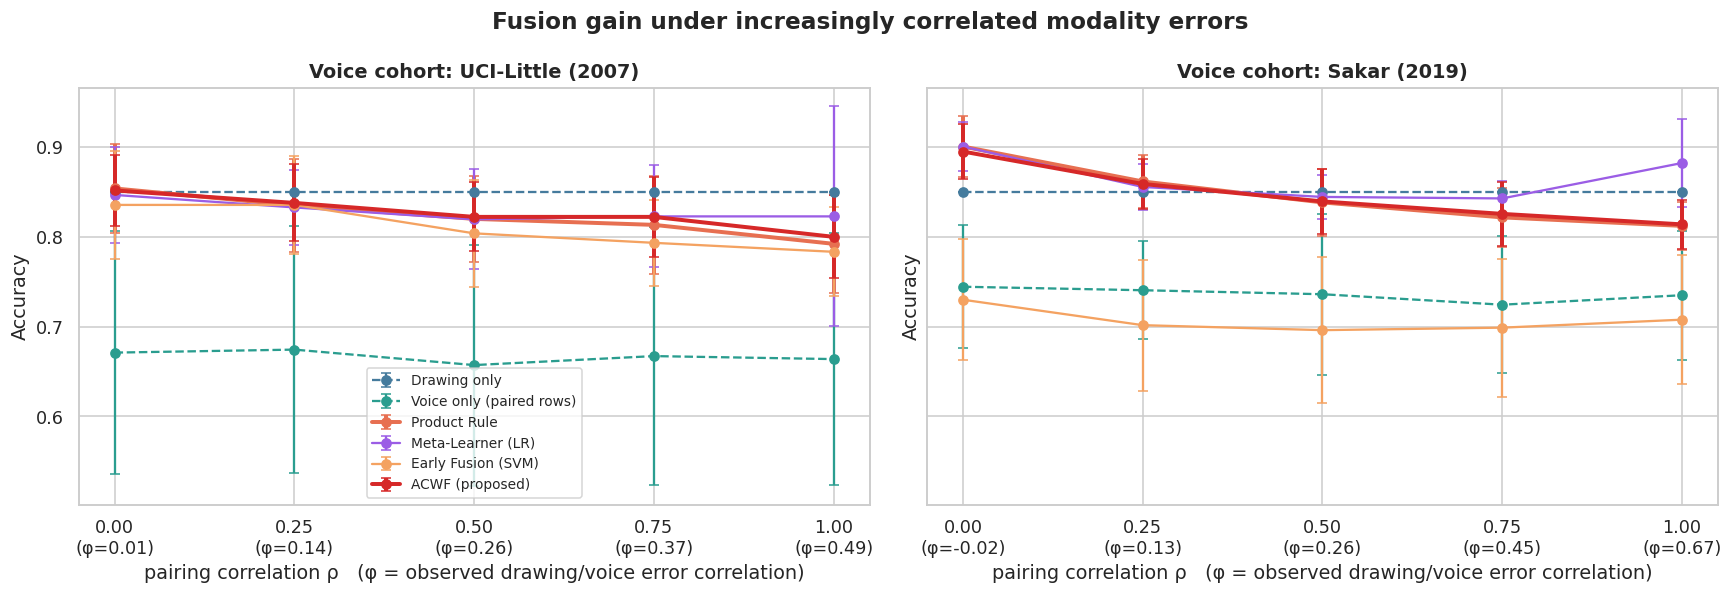

ℹ️ For rho > 0, read the FIXED rules (Product Rule, ACWF). Learned combiners (Meta-Learner, Weighted w) are trained on
   pairs built from labels + model confidence, so at high rho they can exploit the synthetic pairing itself
   (e.g. the Meta-Learner rebound at rho = 1) — that rebound is a simulation artefact, not a real gain.


Method                  ACWF (proposed)  Drawing only  Product Rule
Cohort            rho                                              
Sakar (2019)      0.00           0.8950          0.85        0.9006
                  0.25           0.8589          0.85        0.8617
                  0.50           0.8394          0.85        0.8383
                  0.75           0.8256          0.85        0.8217
                  1.00           0.8139          0.85        0.8122
UCI-Little (2007) 0.00           0.8517          0.85        0.8539
                  0.25           0.8378          0.85        0.8350
                  0.50           0.8222          0.85        0.8200
                  0.75           0.8222          0.85        0.8133
                  1.00           0.8000          0.85        0.7922

In [15]:
# ============================================================
# STEP 14 — ⭐ Correlated-pairing sensitivity analysis
#   How much of the fusion gain survives when drawing and voice errors co-occur
#   (as they would in real patients)?  rho = 0 independent … rho = 1 worst case
# ============================================================
SHOW = ['Drawing only', 'Voice only (paired rows)', 'Product Rule', 'Meta-Learner (LR)', 'Early Fusion (SVM)', 'ACWF (proposed)']
sens = []
for cname in COHORTS:
    for rho in RHO_GRID:
        log = FUS[cname][rho]['log']
        d_acc = np.array([m['Accuracy'] for m in log['Drawing only']])
        for k in SHOW + ['Weighted Late Fusion', 'Early Fusion (XGB)']:
            a = np.array([m['Accuracy'] for m in log[k]])
            sens.append(dict(Cohort=cname, rho=rho, Error_corr=np.mean(FUS[cname][rho]['err']), Method=k,
                             Accuracy=a.mean(), Std=a.std(), AUC=np.mean([m['AUC'] for m in log[k]]),
                             Gain_vs_Drawing=(a - d_acc).mean(),
                             p_vs_Drawing=wilcoxon_greater(a, d_acc) if 'only' not in k else np.nan))
sens = pd.DataFrame(sens)
sens.to_csv(os.path.join(OUT_DIR, 'correlated_pairing_sensitivity.csv'), index=False)

fig, axes = plt.subplots(1, len(COHORTS), figsize=(8 * len(COHORTS), 5.5), sharey=True)
axes = np.atleast_1d(axes)
pal = dict(zip(SHOW, ['#457b9d', '#2a9d8f', '#e76f51', '#9b5de5', '#f4a261', '#d62828']))
for ax, cname in zip(axes, COHORTS):
    s = sens[sens.Cohort == cname]
    for k in SHOW:
        g = s[s.Method == k]
        ax.errorbar(g.rho, g.Accuracy, yerr=g.Std, marker='o', capsize=3, color=pal[k], label=k,
                    lw=2.6 if k in ('ACWF (proposed)', 'Product Rule') else 1.5, ls='--' if 'only' in k else '-')
    ec = s.drop_duplicates('rho')[['rho', 'Error_corr']]
    ax.set_xticks(ec.rho); ax.set_xticklabels([f'{r:.2f}\n(φ={e:.2f})' for r, e in zip(ec.rho, ec.Error_corr)])
    ax.set_xlabel('pairing correlation ρ   (φ = observed drawing/voice error correlation)')
    ax.set_title(f'Voice cohort: {cname}', fontweight='bold'); ax.set_ylabel('Accuracy')
axes[0].legend(fontsize=9)
plt.suptitle('Fusion gain under increasingly correlated modality errors', fontweight='bold')
plt.tight_layout(); savefig('fig11_correlated_pairing_sensitivity.png'); plt.show()
print('ℹ️ For rho > 0, read the FIXED rules (Product Rule, ACWF). Learned combiners (Meta-Learner, Weighted w) are trained on\n'
      '   pairs built from labels + model confidence, so at high rho they can exploit the synthetic pairing itself\n'
      '   (e.g. the Meta-Learner rebound at rho = 1) — that rebound is a simulation artefact, not a real gain.')
display(sens[sens.Method.isin(['Drawing only', 'Product Rule', 'ACWF (proposed)'])]
        .pivot_table(index=['Cohort', 'rho'], columns='Method', values='Accuracy').round(4))

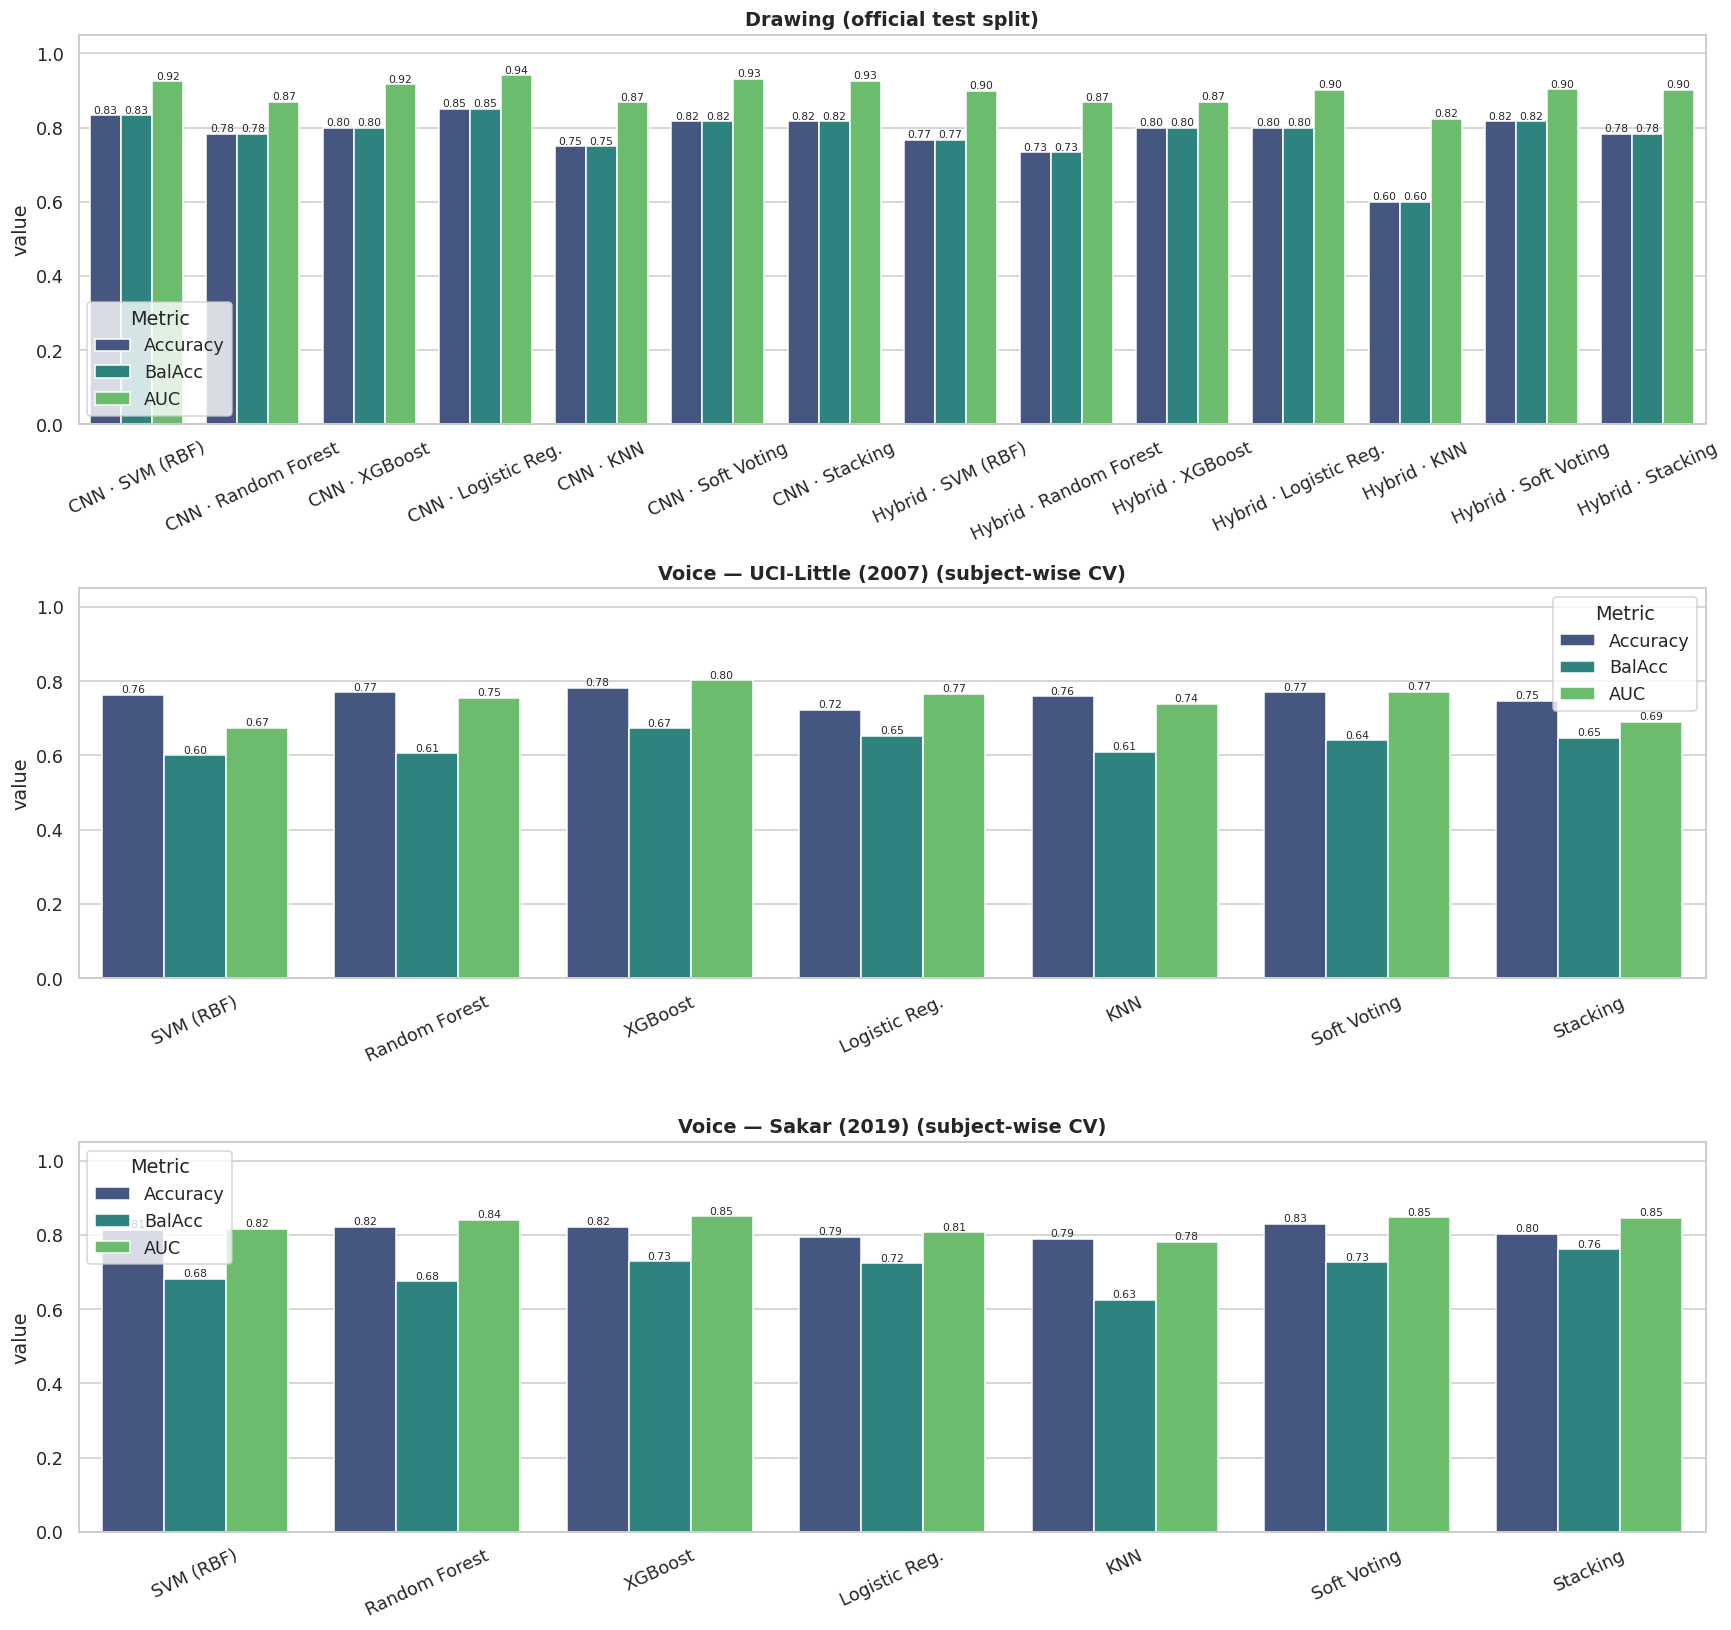

In [16]:
# ============================================================
# STEP 15 — Unimodal model comparison (drawing ablation + both voice cohorts)
# ============================================================
panels = [('Drawing (official test split)', res_d.assign(Model=res_d.FeatureSet.str.split(' ').str[0] + ' · ' + res_d.Model))] + \
         [(f'Voice — {c} (subject-wise CV)', res_v[c]) for c in COHORTS]
fig, axes = plt.subplots(len(panels), 1, figsize=(16, 5 * len(panels)))
for ax, (t, df_) in zip(axes, panels):
    d = df_.melt(id_vars='Model', value_vars=['Accuracy', 'BalAcc', 'AUC'], var_name='Metric')
    sns.barplot(data=d, x='Model', y='value', hue='Metric', ax=ax, palette='viridis')
    ax.set_title(t, fontweight='bold'); ax.set_ylim(0, 1.05); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=25)
    for c in ax.containers: ax.bar_label(c, fmt='%.2f', fontsize=7)
plt.tight_layout(); savefig('fig03_unimodal_comparison.png'); plt.show()

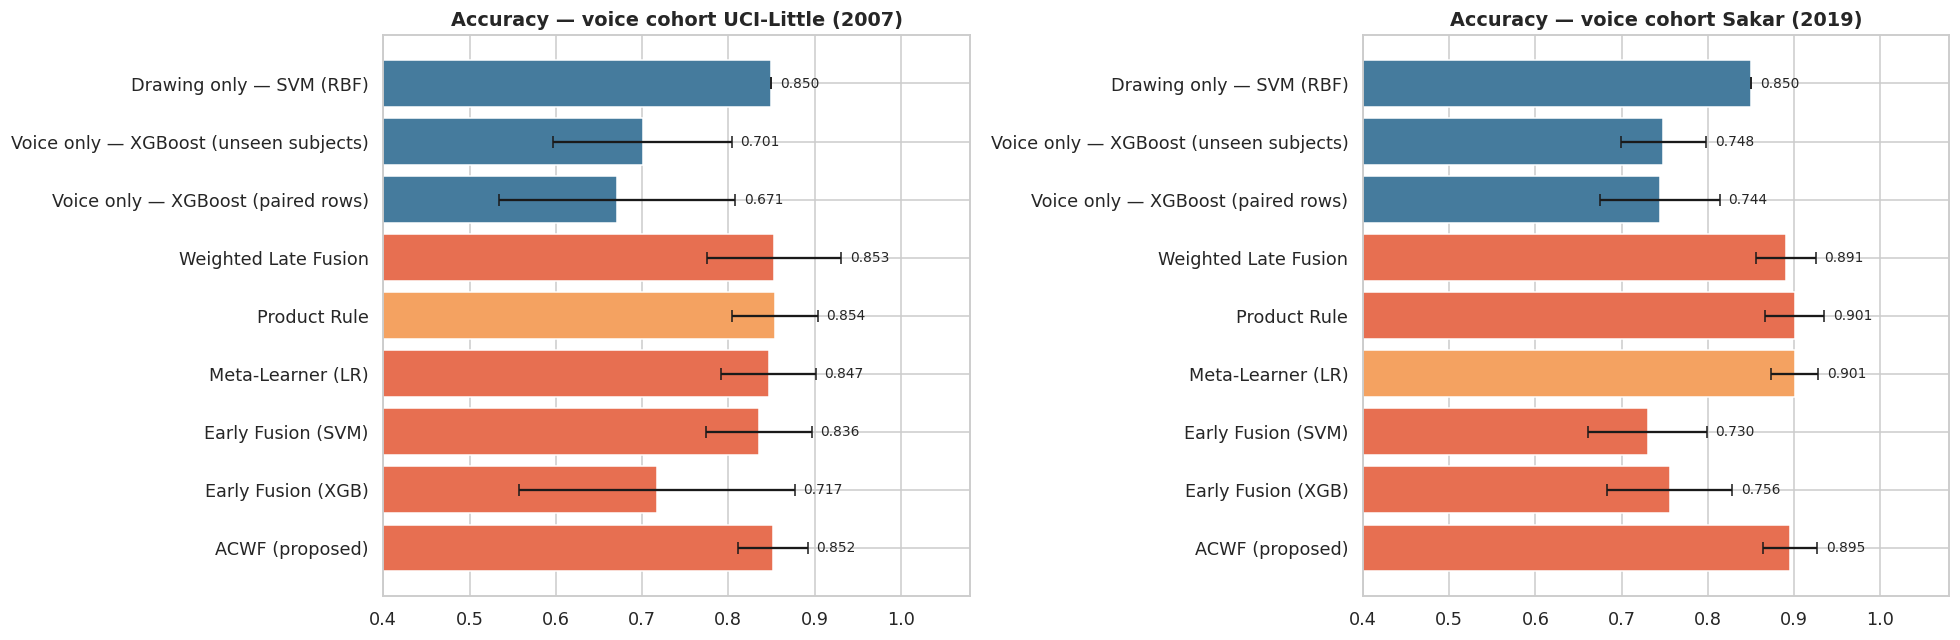

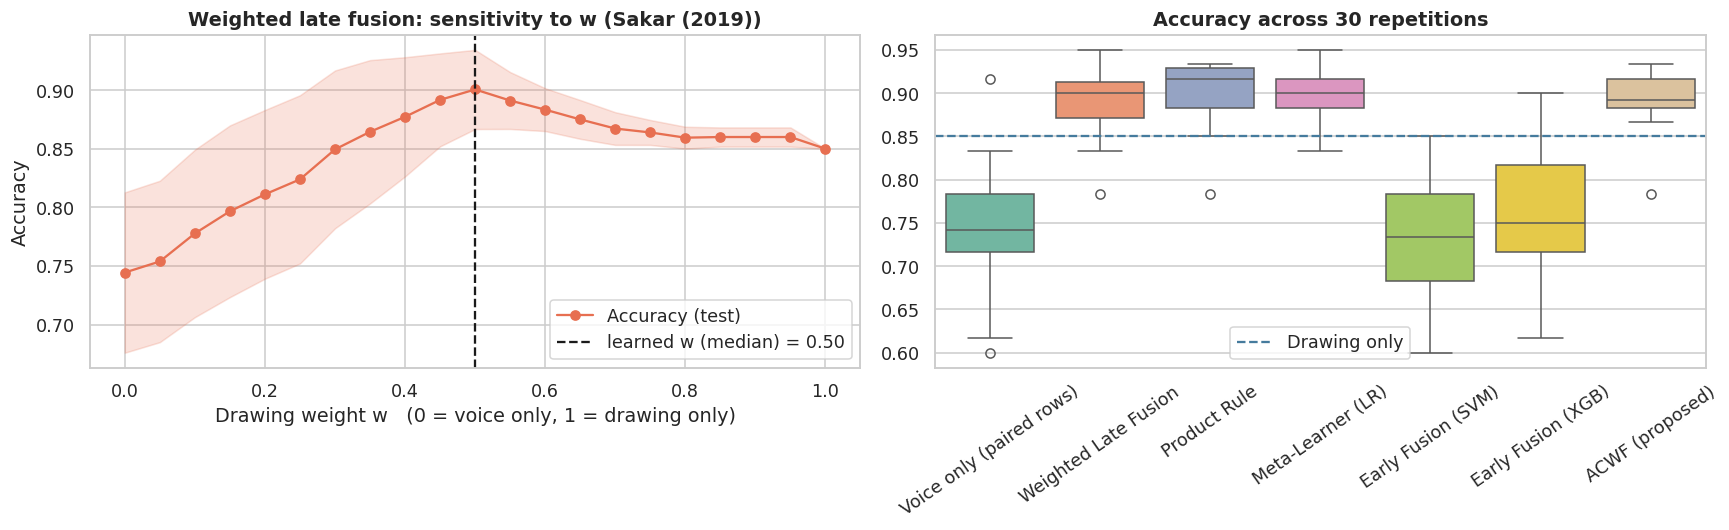

In [17]:
# ============================================================
# STEP 16 — Unimodal vs multimodal (both cohorts) + stability (primary cohort)
# ============================================================
fig, axes = plt.subplots(1, len(COHORTS), figsize=(9 * len(COHORTS), 6), sharex=True)
for ax, cname in zip(np.atleast_1d(axes), COHORTS):
    df_ = FINAL[cname]
    colors = ['#f4a261' if k == BEST_FUSION[cname] else '#457b9d' if t == 'Unimodal' else '#e76f51' for k, t in zip(df_.Key, df_.Type)]
    ax.barh(df_.Approach, df_.Accuracy_mean, xerr=df_.Accuracy_std, color=colors, capsize=4)
    for i, (v, e) in enumerate(zip(df_.Accuracy_mean, df_.Accuracy_std)):
        ax.text(min(v + e + .01, 1.0), i, f'{v:.3f}', va='center', fontsize=9)
    ax.set_xlim(0.4, 1.08); ax.invert_yaxis(); ax.set_title(f'Accuracy — voice cohort {cname}', fontweight='bold')
plt.tight_layout(); savefig('fig04_unimodal_vs_multimodal.png'); plt.show()

P = FUS[PRIMARY_COHORT][0.0]
sw, W_FINAL = np.array(P['sweep']), float(np.median([s['w'] for s in P['store']]))
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(W_GRID, sw.mean(0), 'o-', color='#e76f51', label='Accuracy (test)')
axes[0].fill_between(W_GRID, sw.mean(0) - sw.std(0), sw.mean(0) + sw.std(0), color='#e76f51', alpha=.2)
axes[0].axvline(W_FINAL, ls='--', color='k', label=f'learned w (median) = {W_FINAL:.2f}')
axes[0].set_xlabel('Drawing weight w   (0 = voice only, 1 = drawing only)'); axes[0].set_ylabel('Accuracy')
axes[0].set_title(f'Weighted late fusion: sensitivity to w ({PRIMARY_COHORT})', fontweight='bold'); axes[0].legend()
box = pd.DataFrame({k: [m['Accuracy'] for m in P['log'][k]] for k in ['Voice only (paired rows)'] + STRATS})
sns.boxplot(data=box, ax=axes[1], palette='Set2')
axes[1].axhline(P['log']['Drawing only'][0]['Accuracy'], ls='--', color='#457b9d', label='Drawing only')
axes[1].tick_params(axis='x', rotation=35); axes[1].legend()
axes[1].set_title(f'Accuracy across {N_PAIRINGS} repetitions', fontweight='bold')
plt.tight_layout(); savefig('fig05_fusion_sensitivity_stability.png'); plt.show()

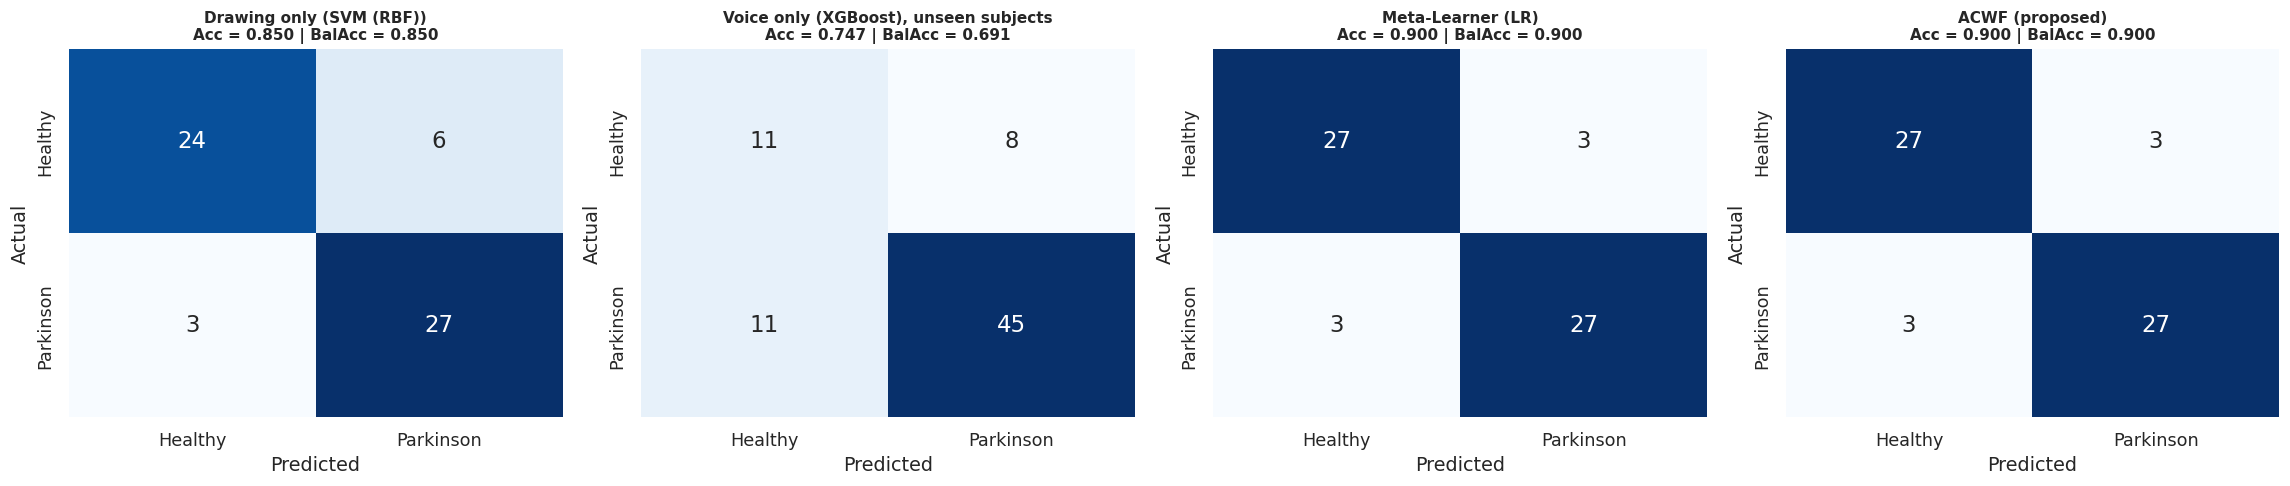

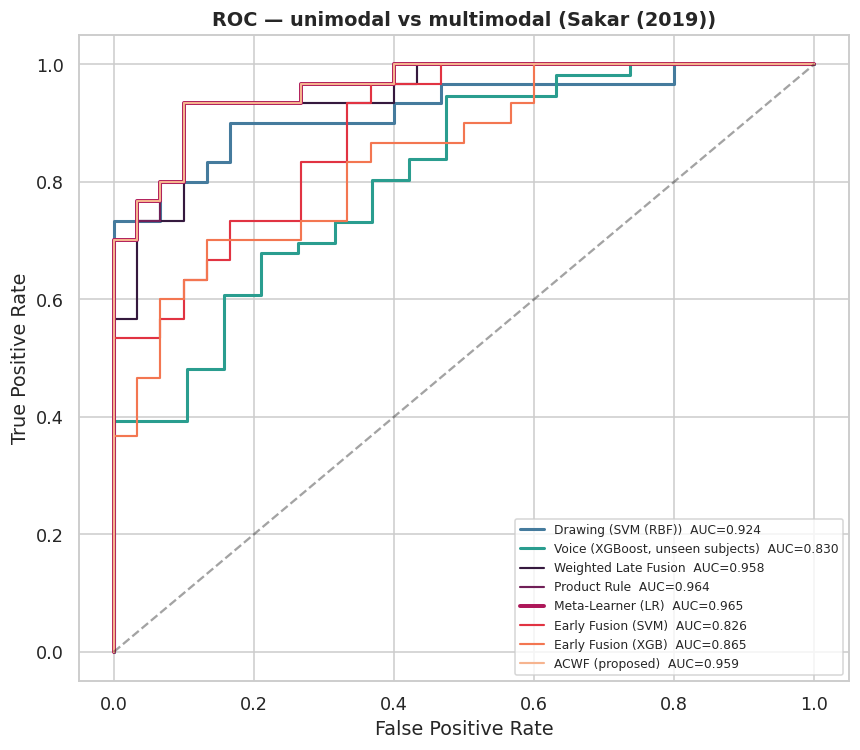

In [18]:
# ============================================================
# STEP 17 — Confusion matrices + ROC (primary cohort, repetition #0)
# ============================================================
s0, CP, BF = P['store'][0], COHORTS[PRIMARY_COHORT], BEST_FUSION[PRIMARY_COHORT]
cms = [(f'Drawing only ({BEST_D})', yd_te, s0['probs']['Drawing only']),
       (f'Voice only ({CP["best"]}), unseen subjects', s0['voice_test_y'], s0['voice_test_p']),
       (BF, yd_te, s0['probs'][BF]), ('ACWF (proposed)', yd_te, s0['probs']['ACWF (proposed)'])]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
for ax, (t, y, p) in zip(axes, cms):
    pred = (p >= .5).astype(int)
    sns.heatmap(confusion_matrix(y, pred, labels=[0, 1]), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={'size': 15})
    ax.set_title(f'{t}\nAcc = {accuracy_score(y, pred):.3f} | BalAcc = {balanced_accuracy_score(y, pred):.3f}', fontweight='bold', fontsize=10)
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); savefig('fig06_confusion_matrices.png'); plt.show()

mean_auc = {k: np.mean([m['AUC'] for m in P['log'][k]]) for k in LOG_KEYS}
plt.figure(figsize=(8, 7))
fpr, tpr, _ = roc_curve(yd_te, s0['probs']['Drawing only'])
plt.plot(fpr, tpr, lw=2, color='#457b9d', label=f'Drawing ({BEST_D})  AUC={mean_auc["Drawing only"]:.3f}')
fpr, tpr, _ = roc_curve(s0['voice_test_y'], s0['voice_test_p'])
plt.plot(fpr, tpr, lw=2, color='#2a9d8f', label=f'Voice ({CP["best"]}, unseen subjects)  AUC={mean_auc["Voice only (subject-wise test)"]:.3f}')
for s, c in zip(STRATS, sns.color_palette('rocket', len(STRATS))):
    fpr, tpr, _ = roc_curve(yd_te, s0['probs'][s])
    plt.plot(fpr, tpr, lw=2.6 if s == BF else 1.4, color=c, label=f'{s}  AUC={mean_auc[s]:.3f}')
plt.plot([0, 1], [0, 1], 'k--', alpha=.4)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title(f'ROC — unimodal vs multimodal ({PRIMARY_COHORT})', fontweight='bold'); plt.legend(fontsize=8, loc='lower right')
plt.tight_layout(); savefig('fig07_roc_curves.png'); plt.show()

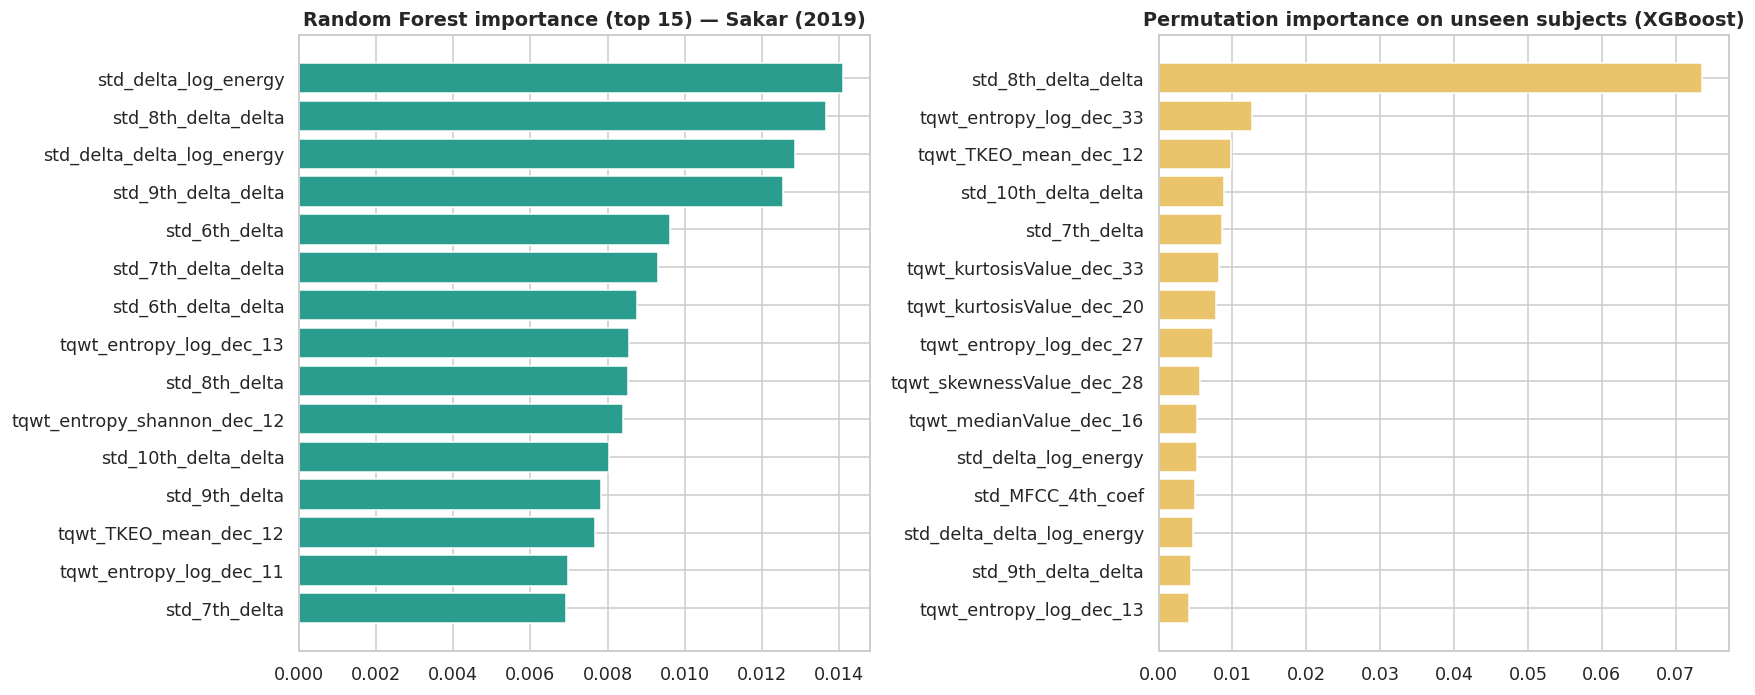

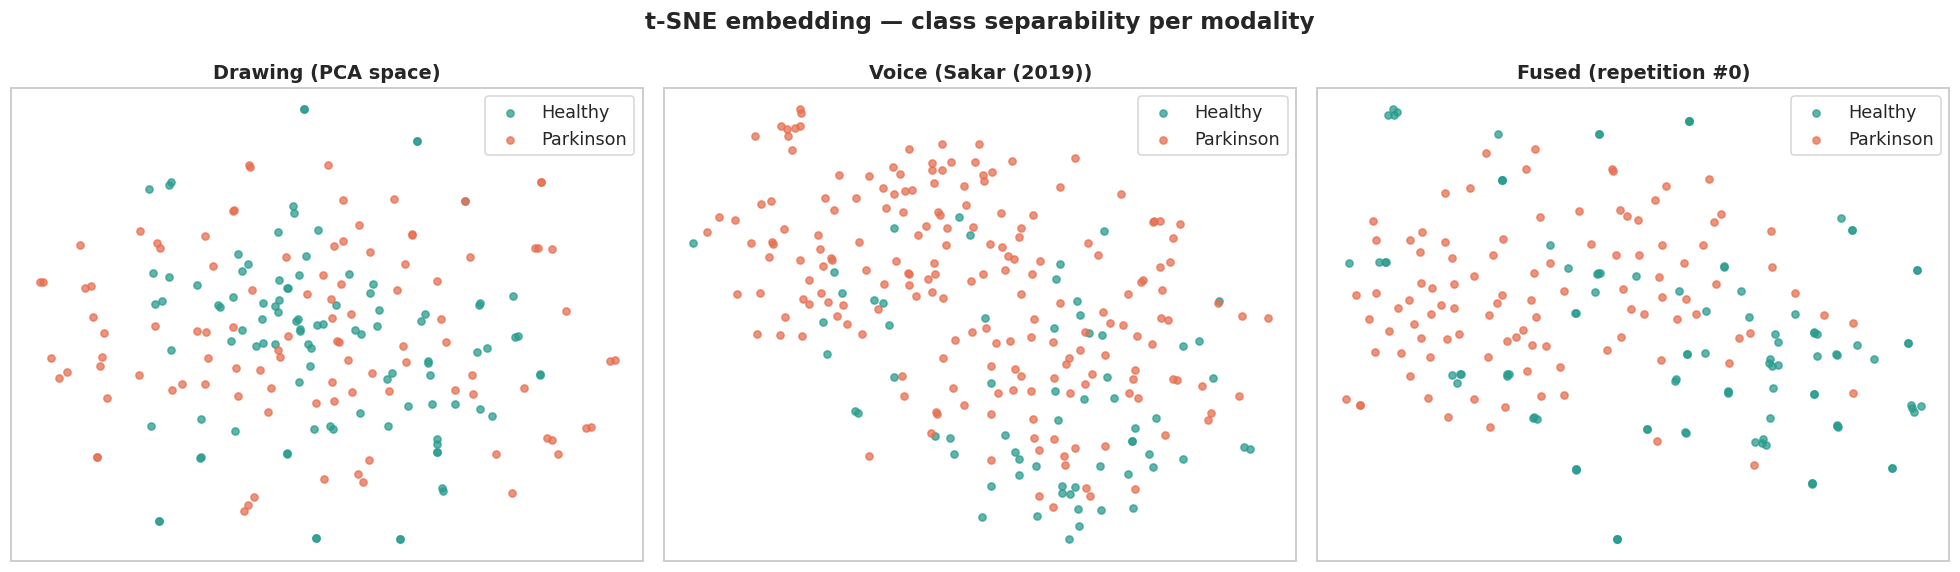

In [19]:
# ============================================================
# STEP 18 — Voice explainability (primary cohort) + t-SNE
# ============================================================
Xp, yp, gp, fp = CP['X'], CP['y'], CP['g'], CP['features']
rf_imp = RandomForestClassifier(n_estimators=500, class_weight='balanced', random_state=SEED, n_jobs=-1).fit(StandardScaler().fit_transform(Xp), yp)
vtr0, vte0 = s0['vtr'], s0['vte']
pipe0 = make_pipeline('voice', model_zoo(CP['spw'])[CP['best']]).fit(Xp[vtr0], yp[vtr0])
pi = permutation_importance(pipe0, Xp[vte0], yp[vte0], n_repeats=10, random_state=SEED, scoring='roc_auc', n_jobs=-1)
imp = pd.DataFrame({'Feature': fp, 'RF_Gini': rf_imp.feature_importances_, 'Permutation_AUC_drop': pi.importances_mean}).sort_values('RF_Gini', ascending=False)
imp.to_csv(os.path.join(OUT_DIR, 'voice_feature_importance.csv'), index=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
top = imp.head(15); axes[0].barh(top.Feature, top.RF_Gini, color='#2a9d8f'); axes[0].invert_yaxis()
axes[0].set_title(f'Random Forest importance (top 15) — {PRIMARY_COHORT}', fontweight='bold')
top2 = imp.sort_values('Permutation_AUC_drop', ascending=False).head(15)
axes[1].barh(top2.Feature, top2.Permutation_AUC_drop, color='#e9c46a'); axes[1].invert_yaxis()
axes[1].set_title(f'Permutation importance on unseen subjects ({CP["best"]})', fontweight='bold')
plt.tight_layout(); savefig('fig08_voice_feature_importance.png'); plt.show()

vsc0 = StandardScaler().fit(Xp[vtr0])
fused = np.vstack([np.hstack([Zd_tr, vsc0.transform(Xp[vtr0])[s0['jtr']]]), np.hstack([Zd_te, vsc0.transform(Xp[vte0])[s0['jte']]])])
spaces = [('Drawing (PCA space)', np.vstack([Zd_tr, Zd_te]), np.r_[yd_tr, yd_te]),
          (f'Voice ({PRIMARY_COHORT})', StandardScaler().fit_transform(Xp), yp),
          ('Fused (repetition #0)', fused, np.r_[yd_tr, yd_te])]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
for ax, (t, X, y) in zip(axes, spaces):
    E = TSNE(n_components=2, perplexity=min(30, len(X) // 4), random_state=SEED, init='pca').fit_transform(StandardScaler().fit_transform(X))
    for c, col in [(0, '#2a9d8f'), (1, '#e76f51')]:
        ax.scatter(E[y == c, 0], E[y == c, 1], s=22, alpha=.75, c=col, label=CLASS_NAMES[c])
    ax.set_title(t, fontweight='bold'); ax.legend(); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('t-SNE embedding — class separability per modality', fontweight='bold')
plt.tight_layout(); savefig('fig09_tsne.png'); plt.show()

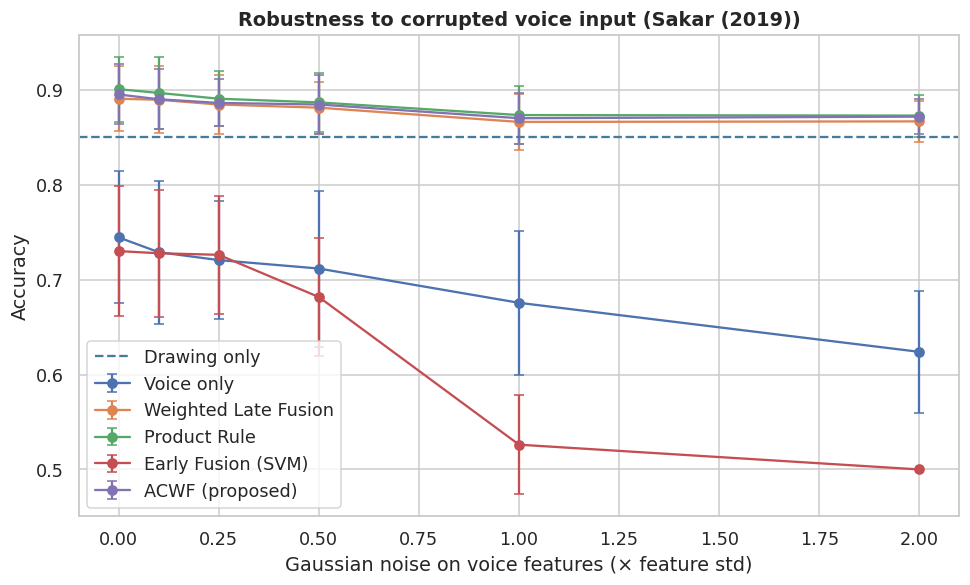

Method,ACWF (proposed),Early Fusion (SVM),Product Rule,Voice only,Weighted Late Fusion
Noise_sigma,,,,,
0.00,0.8950,0.7300,0.9006,0.7444,0.8906
0.10,0.8900,0.7278,0.8967,0.7289,0.8894
0.25,0.8861,0.7261,0.8906,0.7206,0.8844
0.50,0.8844,0.6817,0.8867,0.7117,0.8811
1.00,0.8700,0.5261,0.8733,0.6756,0.8661
2.00,0.8717,0.5000,0.8728,0.6239,0.8667


,Scenario,Accuracy
0,Both modalities (Meta-Learner (LR)),0.9006
1,Both modalities (ACWF),0.8950
2,Voice missing → drawing only,0.8500
3,Drawing missing → voice only,0.7444


In [20]:
# ============================================================
# STEP 19 — Robustness: noisy voice + missing modality (primary cohort)
# ============================================================
rob_df = pd.DataFrame(ROB[PRIMARY_COHORT]).groupby(['Noise_sigma', 'Method'], sort=False).Accuracy.agg(['mean', 'std']).reset_index()
rob_df.to_csv(os.path.join(OUT_DIR, 'robustness_noise.csv'), index=False)
plt.figure(figsize=(9, 5.5))
for name, g in rob_df.groupby('Method', sort=False):
    plt.errorbar(g.Noise_sigma, g['mean'], yerr=g['std'], marker='o', capsize=3, label=name)
plt.axhline(P['log']['Drawing only'][0]['Accuracy'], ls='--', color='#457b9d', label='Drawing only')
plt.xlabel('Gaussian noise on voice features (× feature std)'); plt.ylabel('Accuracy')
plt.title(f'Robustness to corrupted voice input ({PRIMARY_COHORT})', fontweight='bold'); plt.legend()
plt.tight_layout(); savefig('fig10_robustness_noise.png'); plt.show()

acc = lambda k: np.mean([m['Accuracy'] for m in P['log'][k]])
missing = pd.DataFrame([
    dict(Scenario=f'Both modalities ({BF})', Accuracy=acc(BF)),
    dict(Scenario='Both modalities (ACWF)', Accuracy=acc('ACWF (proposed)')),
    dict(Scenario='Voice missing → drawing only', Accuracy=acc('Drawing only')),
    dict(Scenario='Drawing missing → voice only', Accuracy=acc('Voice only (paired rows)'))])
missing.to_csv(os.path.join(OUT_DIR, 'robustness_missing_modality.csv'), index=False)
display(rob_df.pivot(index='Noise_sigma', columns='Method', values='mean').round(4))
display(missing.round(4))

In [21]:
# ============================================================
# STEP 20 — Deployable models + inference (drawing image + optional voice) — uses ACWF
# ============================================================
# Deployment voice cohort = UCI-Little: its 22 MDVP features can be computed from a phone
# recording with Praat/parselmouth, whereas Sakar's 750+ TQWT/MFCC features need a heavier pipeline.
CD = COHORTS[DEPLOY_COHORT]
fit_v_final = make_pipeline('voice', model_zoo(CD['spw'])[CD['best']]).fit(CD['X'], CD['y'])
cal_v_final = PlattCalibrator().fit(voice_oof[DEPLOY_COHORT][CD['best']][0], CD['y'])
REL_V_FINAL = max(roc_auc_score(CD['y'], voice_oof[DEPLOY_COHORT][CD['best']][0]) - 0.5, 0.01)
GAMMA_FINAL = float(pd.Series([s['gamma'] for s in FUS[DEPLOY_COHORT][0.0]['store']]).mode().iloc[0])

def predict_multimodal(image_path=None, voice_features=None):
    out, pd_, pv_ = {}, None, None
    if image_path is not None:
        pd_ = float(cal_d.transform(draw_pipe.predict_proba(drawing_features([image_path], DRAW_FEATURE_SET))[:, 1])[0])
        out['p_parkinson_drawing'] = round(pd_ * 100, 2)
    if voice_features is not None:
        v = np.array([voice_features[f] for f in CD['features']] if isinstance(voice_features, dict) else voice_features,
                     dtype=np.float32)[None]
        pv_ = float(cal_v_final.transform(fit_v_final.predict_proba(v)[:, 1])[0]); out['p_parkinson_voice'] = round(pv_ * 100, 2)
    if pd_ is not None and pv_ is not None:
        p = float(acwf(np.array([pd_]), np.array([pv_]), REL_D, REL_V_FINAL, GAMMA_FINAL)[0]); out['mode'] = 'multimodal (ACWF)'
    elif pd_ is not None:
        p = pd_; out['mode'] = 'drawing only'
    elif pv_ is not None:
        p = pv_; out['mode'] = 'voice only'
    else:
        raise ValueError('Give at least one modality')
    out.update(prediction=CLASS_NAMES[int(p >= .5)], p_parkinson=round(p * 100, 2), p_healthy=round((1 - p) * 100, 2))
    return out

te_rows = draw_df[~tr_mask].reset_index(drop=True)
for c in (0, 1):
    i, j = int(np.where(te_rows.label == c)[0][0]), int(np.where(CD['y'] == c)[0][0])
    print(f'True = {CLASS_NAMES[c]:9s} →', predict_multimodal(te_rows.path[i], dict(zip(CD['features'], CD['X'][j]))))

True = Healthy   → {'p_parkinson_drawing': 22.39, 'p_parkinson_voice': 7.32, 'mode': 'multimodal (ACWF)', 'prediction': 'Healthy', 'p_parkinson': 11.38, 'p_healthy': 88.62}
True = Parkinson → {'p_parkinson_drawing': 56.26, 'p_parkinson_voice': 84.5, 'mode': 'multimodal (ACWF)', 'prediction': 'Parkinson', 'p_parkinson': 83.62, 'p_healthy': 16.38}


In [22]:
# ============================================================
# STEP 21 — Save all artifacts & download
# ============================================================
joblib.dump(draw_pipe,   os.path.join(MODEL_DIR, 'MM_drawing_pipeline.pkl'))
joblib.dump(cal_d,       os.path.join(MODEL_DIR, 'MM_drawing_calibrator.pkl'))
joblib.dump(fit_v_final, os.path.join(MODEL_DIR, 'MM_voice_pipeline.pkl'))
joblib.dump(cal_v_final, os.path.join(MODEL_DIR, 'MM_voice_calibrator.pkl'))
cnn_extractor.save(os.path.join(MODEL_DIR, 'mobilenet_extractor.keras'))

import sklearn
config = dict(
    version='V3', drawing=dict(feature_set=DRAW_FEATURE_SET, model=BEST_D,
                               hog=dict(size=128, orientations=9, pixels_per_cell=8, cells_per_block=2), lbp=dict(P=24, R=3, bins=26)),
    voice_cohorts={c: dict(desc=C['desc'], best_model=C['best'], n_features=len(C['features'])) for c, C in COHORTS.items()},
    deploy=dict(voice_cohort=DEPLOY_COHORT, voice_features=CD['features'], fusion='ACWF', acwf_gamma=GAMMA_FINAL,
                reliability_drawing=round(REL_D, 4), reliability_voice=round(REL_V_FINAL, 4)),
    best_fusion=BEST_FUSION,
    protocol=dict(voice='subject-wise (StratifiedGroupKFold / held-out subjects)', voice_test_fraction=VOICE_TEST_FRAC,
                  repetitions=N_PAIRINGS, voice_cv_repeats=N_VOICE_REPEATS, rho_grid=list(RHO_GRID)),
    external_validation=bool(EXT_OK), finetune_baseline=bool(RUN_FINETUNE),
    versions=dict(sklearn=sklearn.__version__, tensorflow=tf.__version__, numpy=np.__version__))
with open(os.path.join(MODEL_DIR, 'MM_config.json'), 'w') as f:
    json.dump(config, f, indent=2)

zip_base = os.path.join(BASE_DIR, 'multimodal_PD_results_V3')
shutil.make_archive(zip_base, 'zip', OUT_DIR)
print('📦 Saved:', zip_base + '.zip')
for root, _, fs in os.walk(OUT_DIR):
    for f in sorted(fs):
        print('   ', os.path.relpath(os.path.join(root, f), OUT_DIR))
if IN_COLAB:
    colab_files.download(zip_base + '.zip')

📦 Saved: /content/multimodal_PD_results_V3.zip
    correlated_pairing_sensitivity.csv
    external_validation_newhandpd.csv
    finetune_baseline_runs.csv
    lightweight_comparison.csv
    multimodal_results_raw.csv
    multimodal_results_table.csv
    robustness_missing_modality.csv
    robustness_noise.csv
    statistical_tests.csv
    unimodal_all_models.csv
    voice_feature_importance.csv
    figures/fig01_voice_distributions.png
    figures/fig02_voice_correlation.png
    figures/fig02b_sakar_top_features.png
    figures/fig03_unimodal_comparison.png
    figures/fig04_unimodal_vs_multimodal.png
    figures/fig05_fusion_sensitivity_stability.png
    figures/fig06_confusion_matrices.png
    figures/fig07_roc_curves.png
    figures/fig08_voice_feature_importance.png
    figures/fig09_tsne.png
    figures/fig10_robustness_noise.png
    figures/fig11_correlated_pairing_sensitivity.png
    figures/fig12_hybrid_vs_finetune.png
    figures/fig13_external_validation.png
    models/MM_con

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
# ============================================================
# STEP 22 — Paper-ready summary
# ============================================================
print('=' * 92)
print('  MULTIMODAL PD DETECTION — V3 SUMMARY')
print('=' * 92)
print(f'Drawing : {len(draw_df)} images | best = {FS_LABEL[DRAW_FEATURE_SET]} + {BEST_D} '
      f'(PCA {draw_pipe.named_steps["pca"].n_components_} comps)')
for c, C in COHORTS.items():
    print(f'Voice   : {c:18s} {C["desc"]} | best = {C["best"]}')
if RUN_FINETUNE:
    print(f'Fine-tuned MobileNetV2 baseline: Acc {light.Accuracy.iloc[1]*100:.2f} ± {light.Acc_std.iloc[1]*100:.2f}% '
          f'| train {light.Train_time_s.iloc[1]:.0f}s vs hybrid {light.Train_time_s.iloc[0]:.0f}s')
if EXT_OK:
    print(f'External (NewHandPD): zero-shot Acc {ext_results.Accuracy.iloc[0]*100:.2f}% | '
          f're-trained subject-wise CV Acc {ext_results.Accuracy.iloc[2]*100:.2f}%')
for c in COHORTS:
    print('-' * 92); print(f'[{c}]  (independent pairing, {N_PAIRINGS} repetitions)')
    for r in FINAL[c].itertuples():
        print(f'  {r.Approach:46s} Acc {r.Accuracy_mean*100:6.2f} ± {r.Accuracy_std*100:5.2f}%  BalAcc {r.BalAcc_mean*100:6.2f}%  AUC {r.AUC_mean:.3f}')
    print(f'  🏆 best fusion: {BEST_FUSION[c]} | better than both unimodal (p<0.05): '
          + (', '.join(sig[(sig.Cohort == c) & sig.Better_than_both].Strategy) or 'none'))
    for k in ('Product Rule', 'ACWF (proposed)'):
        s = sens[(sens.Cohort == c) & (sens.Method == k)]
        print(f'  correlated-pairing gain vs drawing [{k}]: ' + ' | '.join(f'ρ={r.rho:.2f}: {r.Gain_vs_Drawing*100:+.1f}%' for r in s.itertuples()))
print('=' * 92)

  MULTIMODAL PD DETECTION — V3 SUMMARY
Drawing : 204 images | best = CNN (MobileNetV2) + SVM (RBF) (PCA 95 comps)
Voice   : UCI-Little (2007)  195 recordings / 32 subject IDs, 22 features | best = XGBoost
Voice   : Sakar (2019)       252 subjects (1 row each), 751 features | best = XGBoost
Fine-tuned MobileNetV2 baseline: Acc 82.22 ± 3.47% | train 301s vs hybrid 29s
External (NewHandPD): zero-shot Acc 46.97% | re-trained subject-wise CV Acc 90.15%
--------------------------------------------------------------------------------------------
[UCI-Little (2007)]  (independent pairing, 30 repetitions)
  Drawing only — SVM (RBF)                       Acc  85.00 ±  0.00%  BalAcc  85.00%  AUC 0.924
  Voice only — XGBoost (unseen subjects)         Acc  70.07 ± 10.34%  BalAcc  67.35%  AUC 0.757
  Voice only — XGBoost (paired rows)             Acc  67.11 ± 13.72%  BalAcc  67.11%  AUC 0.749
  Weighted Late Fusion                           Acc  85.33 ±  7.75%  BalAcc  85.33%  AUC 0.929
  Product Ru